# 0
# مشخصات و محیط اجرا

In [ ]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import seaborn as sns
import random
import sys
import platform
import sklearn

print("=================================================================")
print("ENVIRONMENT INFORMATION")
print("=================================================================\n")

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Python version:", sys.version)
print("Platform:", platform.platform())
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Tensorflow version:", tf.__version__)

ENVIRONMENT INFORMATION

PyTorch version: 2.14.1+cpu
CUDA available: False
Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
NumPy version: 2.4.6
Pandas version: 2.2.3
Scikit-learn version: 1.6.1
Tensorflow version: 2.21.0


# 1
# مجموعه داده
# 1-1
# بررسی مجموعه داده

i) Upload dataset and show the number of samples and features

In [ ]:
!pip install ucimlrepo

In [ ]:

from ucimlrepo import fetch_ucirepo

predict_students_dropout_and_academic_success = fetch_ucirepo(id=697)
x = predict_students_dropout_and_academic_success.data.features
y = predict_students_dropout_and_academic_success.data.targets

x.columns = x.columns.str.strip()   # removes leading and trailing spaces from column names

In [ ]:
print("=================================================================")
print("DATASET INFORMATION (Only Features)")
print("=================================================================")

df = pd.concat([x,y], axis=1)

print("Dataset shape:", df.shape)

print("\nFirst five observations:")

display(df.head())

print("\nLast five observations:")

display(df.tail())

print("\nColumn names:")

for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

DATASET INFORMATION (Only Features)
Dataset shape: (4424, 37)

First five observations:


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate



Last five observations:


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4423,1,10,1,9773,1,1,152.0,22,38,37,...,0,6,6,6,13.000000,0,12.7,3.7,-1.70,Graduate



Column names:
01. Marital Status
02. Application mode
03. Application order
04. Course
05. Daytime/evening attendance
06. Previous qualification
07. Previous qualification (grade)
08. Nacionality
09. Mother's qualification
10. Father's qualification
11. Mother's occupation
12. Father's occupation
13. Admission grade
14. Displaced
15. Educational special needs
16. Debtor
17. Tuition fees up to date
18. Gender
19. Scholarship holder
20. Age at enrollment
21. International
22. Curricular units 1st sem (credited)
23. Curricular units 1st sem (enrolled)
24. Curricular units 1st sem (evaluations)
25. Curricular units 1st sem (approved)
26. Curricular units 1st sem (grade)
27. Curricular units 1st sem (without evaluations)
28. Curricular units 2nd sem (credited)
29. Curricular units 2nd sem (enrolled)
30. Curricular units 2nd sem (evaluations)
31. Curricular units 2nd sem (approved)
32. Curricular units 2nd sem (grade)
33. Curricular units 2nd sem (without evaluations)
34. Unemployment rate


ii) Split columns into numerical and categorical (nominal and ordinal) features

In [ ]:
# Split into numerical & categorical features

numerical_feat = x[[
    'Previous qualification (grade)',
    'Admission grade',
    'Age at enrollment',
    'Curricular units 1st sem (credited)',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)',
    'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (credited)',
    'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)',
    'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)',
    'Curricular units 2nd sem (without evaluations)',
    'Unemployment rate',
    'Inflation rate',
    'GDP'
]]

categorical_feat_ordinal = x[[
    'Application order',
    'Previous qualification',
    "Mother's qualification",
    "Father's qualification"
]]

categorical_feat_nominal = x[[
    'Marital Status',
    'Application mode',
    'Course',
    "Daytime/evening attendance",
    'Nacionality',
    "Mother's occupation",
    "Father's occupation",
    'Displaced',
    'Educational special needs',
    'Debtor',
    'Tuition fees up to date',
    'Gender',
    'Scholarship holder',
    'International'
]]

# display info
print("========================================================================")
print("======================== Numerical Features ============================")
print("========================================================================")
numerical_feat.info()
print("========================================================================")
print("================= Categorical Features (Ordinal)========================")
print("========================================================================")
categorical_feat_ordinal.info()
print("========================================================================")
print("================= Categorical Features (Nominal)========================")
print("========================================================================")
categorical_feat_nominal.info()


======================== Numerical Features ============================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 18 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Previous qualification (grade)                  4424 non-null   float64
 1   Admission grade                                 4424 non-null   float64
 2   Age at enrollment                               4424 non-null   int64  
 3   Curricular units 1st sem (credited)             4424 non-null   int64  
 4   Curricular units 1st sem (enrolled)             4424 non-null   int64  
 5   Curricular units 1st sem (evaluations)          4424 non-null   int64  
 6   Curricular units 1st sem (approved)             4424 non-null   int64  
 7   Curricular units 1st sem (grade)                4424 non-null   float64
 8   Curricular units 1st sem (without evaluations

iii) Calculate statistical characteristics for Numerical features

In [ ]:
# Min, Max, Average, Median, Standard Deviation

stats = numerical_feat.describe().T[['min', 'max', 'mean', '50%', 'std']]
stats.columns = ['Min', 'Max', 'Average', 'Median', 'Standard Deviation']
print(stats.round(3).to_string())

                                                  Min      Max  Average   Median  Standard Deviation
Previous qualification (grade)                  95.00  190.000  132.613  133.100              13.188
Admission grade                                 95.00  190.000  126.978  126.100              14.482
Age at enrollment                               17.00   70.000   23.265   20.000               7.588
Curricular units 1st sem (credited)              0.00   20.000    0.710    0.000               2.361
Curricular units 1st sem (enrolled)              0.00   26.000    6.271    6.000               2.480
Curricular units 1st sem (evaluations)           0.00   45.000    8.299    8.000               4.179
Curricular units 1st sem (approved)              0.00   26.000    4.707    5.000               3.094
Curricular units 1st sem (grade)                 0.00   18.875   10.641   12.286               4.844
Curricular units 1st sem (without evaluations)   0.00   12.000    0.138    0.000           

iv) Histogram & Box plot for three features

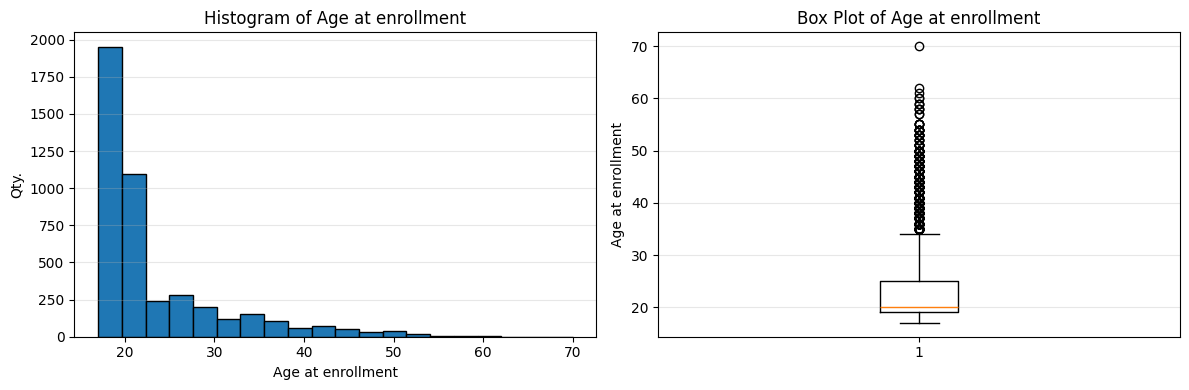

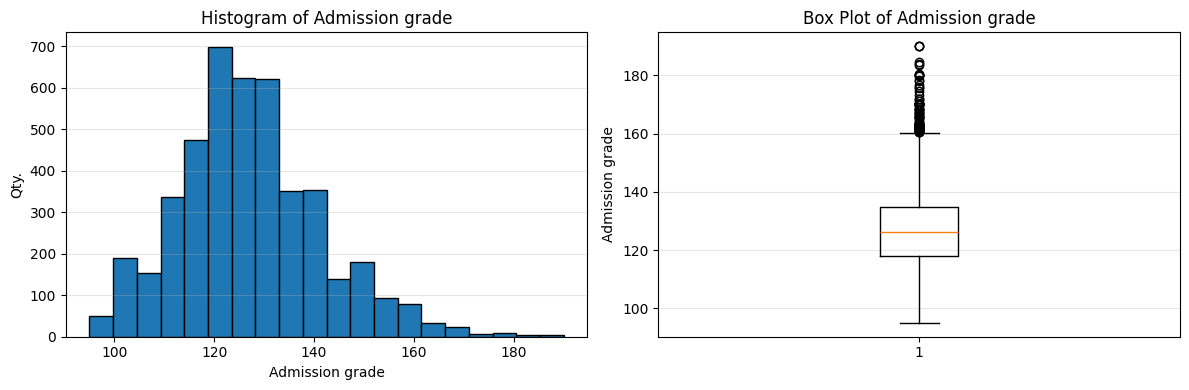

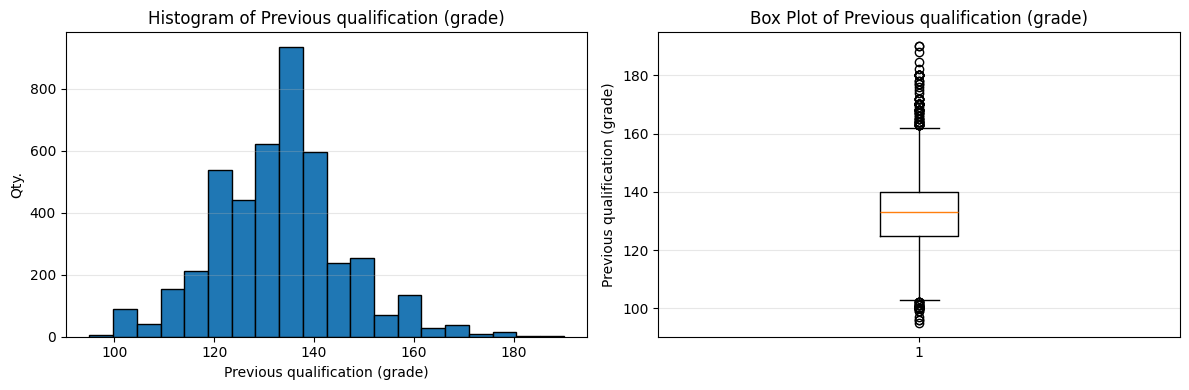

In [ ]:
# Histogram & Box plot
features = ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)']
for feat in features:
  fig, axes = plt.subplots(1, 2, figsize=(12,4))

  # Histogram
  axes[0].hist(x[feat].dropna(), bins=20, edgecolor='black')
  axes[0].set_title(f"Histogram of {feat}")
  axes[0].set_xlabel(feat)
  axes[0].set_ylabel('Qty.')
  axes[0].grid(axis='y', alpha=0.3)

  # Box plot
  axes[1].boxplot(x[feat].dropna(), vert=True)
  axes[1].set_title(f"Box Plot of {feat}")
  axes[1].set_ylabel(feat)
  axes[1].grid(axis='y', alpha=0.3)

  plt.tight_layout()
  plt.show

v) Show missing values and duplicated rows

In [ ]:
# Missing & Duplicate values

print("Missing values: ", x.isnull().sum()[x.isnull().sum() > 0])
print("Duplicate rows: ", x.duplicated().sum())

Missing values:  Series([], dtype: int64)
Duplicate rows:  0


vi) Quantity & percentage of three features


Age at enrollment
 Age at enrollment  Qty.  Percentage (%)
                17     5            0.11
                18  1036           23.42
                19   911           20.59
                20   599           13.54
                21   322            7.28
                22   174            3.93
                23   108            2.44
                24   131            2.96
                25    93            2.10
                26    94            2.12
                27    91            2.06
                28    83            1.88
                29    66            1.49
                30    49            1.11
                31    55            1.24
                32    61            1.38
                33    45            1.02
                34    60            1.36
                35    49            1.11
                36    35            0.79
                37    42            0.95
                38    29            0.66
                39    38            0.

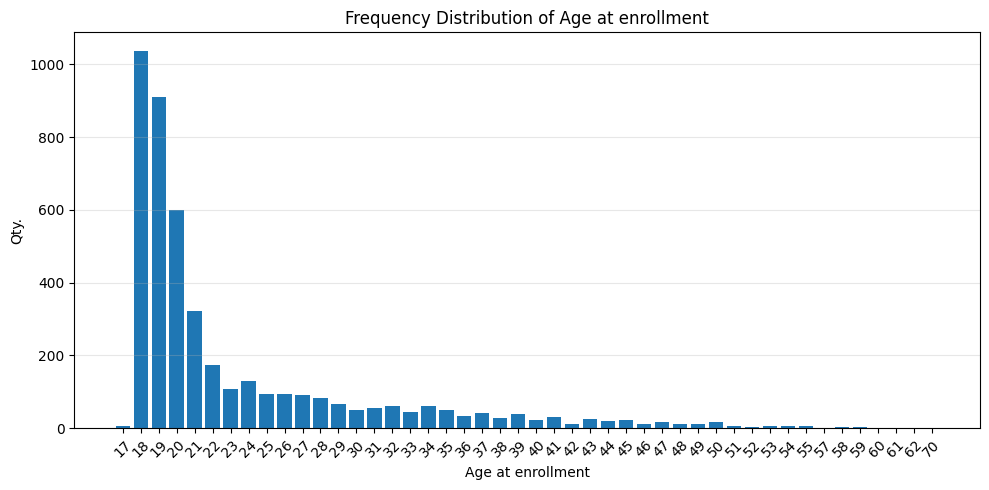


Admission grade
 Admission grade  Qty.  Percentage (%)
            95.0    11            0.25
            95.1     1            0.02
            95.5     2            0.05
            95.8     1            0.02
            96.0     7            0.16
            96.1     1            0.02
            96.7     1            0.02
            97.0     6            0.14
            97.2     1            0.02
            97.4     1            0.02
            97.5     1            0.02
            98.0     3            0.07
            98.1     1            0.02
            98.5     1            0.02
            98.6     2            0.05
            98.7     1            0.02
            98.9     2            0.05
            99.0     3            0.07
            99.3     1            0.02
            99.5     1            0.02
            99.6     1            0.02
            99.7     1            0.02
           100.0   116            2.62
           100.1     2            0.05
        

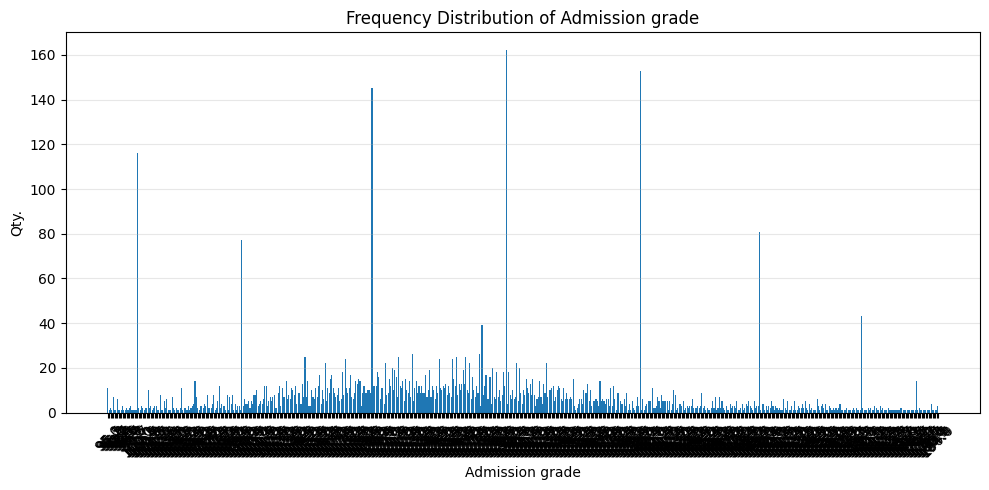


Previous qualification (grade)
 Previous qualification (grade)  Qty.  Percentage (%)
                           95.0     1            0.02
                           96.0     2            0.05
                           97.0     1            0.02
                           99.0     2            0.05
                          100.0    76            1.72
                          101.0     6            0.14
                          102.0     5            0.11
                          103.0     3            0.07
                          105.0     4            0.09
                          106.0    10            0.23
                          107.0     5            0.11
                          108.0    15            0.34
                          109.0     6            0.14
                          110.0   101            2.28
                          111.0    18            0.41
                          112.0    17            0.38
                          113.0    18            0

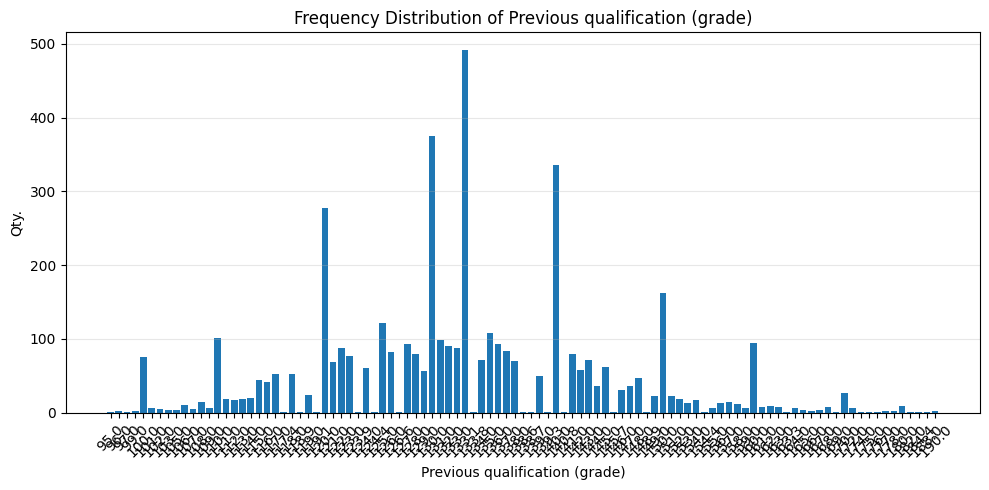

In [ ]:
# Qty & Percentage of the three parameter:
# 1. Age at enrollment
# 2. Adimission grade
# 3. Previous qualification (grade)

features = ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)']
for feat in features:

  # table
  table = x[feat].value_counts().sort_index().reset_index()
  table.columns = [feat, 'Qty.']
  table['Percentage (%)'] = (table['Qty.'] / len(x) * 100)

  print(f"\n{feat}")
  print(table.round(2).to_string(index=False))

  # Bar chart
  plt.figure(figsize=(10,5))
  plt.bar(table[feat].astype(str), table['Qty.'])
  plt.title(f'Frequency Distribution of {feat}')
  plt.xlabel(feat)
  plt.ylabel('Qty.')
  plt.xticks(rotation=45)
  plt.grid(axis='y', alpha=0.3)
  plt.tight_layout()
  plt.show()

# 1-2
# پیش پردازش مجموعه داده

i) Convert categorical features into numerical representation

In [ ]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# One-Hot Encoding for nominal features and binary features
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
nominal_encoded = ohe.fit_transform(categorical_feat_nominal)
nominal_encoded = pd.DataFrame(
    nominal_encoded,
    columns = ohe.get_feature_names_out(categorical_feat_nominal.columns),
    index   = x.index
)

# Ordinal Encoding for ordinal features
oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
ordinal_encoded = oe.fit_transform(categorical_feat_ordinal)
ordinal_encoded = pd.DataFrame(
    ordinal_encoded,
    columns = categorical_feat_ordinal.columns,
    index   =x.index
)

ii) Standard Scaler for numerical features

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numerical_scaled = pd.DataFrame(
    scaler.fit_transform(numerical_feat),
    columns = numerical_feat.columns,
    index   = numerical_feat.index
)

iii) Encode target label (Graduate / Dropout / Enrolled)

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(y)
y_encoded = pd.DataFrame(y_encoded)

counts = np.bincount(y_encoded.values.flatten(), minlength=3)
for i in range(3):
    print(f"Class {i}: {counts[i]}")

Class 0: 1421
Class 1: 794
Class 2: 2209


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


iv) Combine all features into x_encoded

In [ ]:
# combine numerical and categorical features into x
x_encoded = pd.concat([numerical_scaled, ordinal_encoded, nominal_encoded], axis=1)
x_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Columns: 178 entries, Previous qualification (grade) to International_1
dtypes: float64(178)
memory usage: 6.0 MB


# 1-3
# آماده سازی مجموعه داده

i) Split data into train, validation and test

In [ ]:
# Split into train, validation and test

from sklearn.model_selection import train_test_split

# training (70%), test+val (30%)
x_train, x_temp, y_train, y_temp = train_test_split(
    x_encoded, y_encoded,
    test_size    = 0.3,
    random_state = 42,
    stratify     = y
)

# val (15%), test (15%)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp,
    test_size    = 0.5,
    random_state = 42,
    stratify     = y_temp
)

print("Train      : ", x_train.shape , y_train.shape)
print("Validation : ", x_val.shape   , y_val.shape)
print("Test       : ", x_test.shape  , y_test.shape)

Train      :  (3096, 178) (3096, 1)
Validation :  (664, 178) (664, 1)
Test       :  (664, 178) (664, 1)


,Split,Class,Count,Percentage (%)
0,Train,Dropout,994,32.11
1,Train,Enrolled,556,17.96
2,Train,Graduate,1546,49.94
3,Test,Dropout,214,32.23
4,Test,Enrolled,119,17.92
5,Test,Graduate,331,49.85
6,Validation,Dropout,213,32.08
7,Validation,Enrolled,119,17.92
8,Validation,Graduate,332,50.00


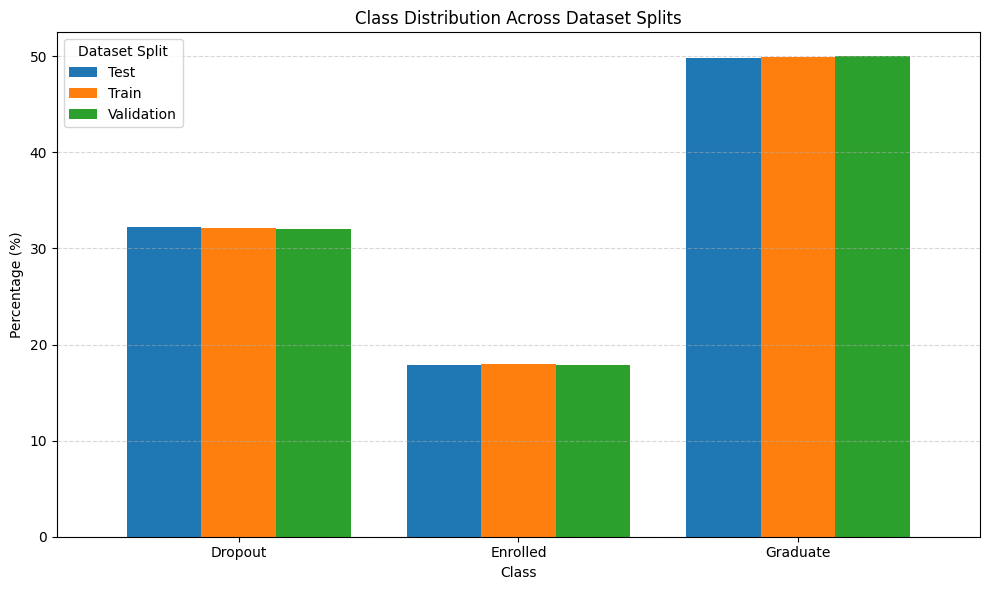

In [ ]:
#### Show count and percentage of each class inside each split

class_names = {
    0: 'Dropout',
    1: 'Enrolled',
    2: 'Graduate'
}

def get_class_distribution(y, split_name):
    if isinstance(y, pd.DataFrame):
        y = y.iloc[:, 0]
    elif isinstance(y, pd.Series):
        pass
    else:
        y = pd.Series(y.flatten())

    counts = y.value_counts().reindex([0, 1, 2], fill_value=0)
    percentages = counts / len(y) * 100

    return pd.DataFrame({
        'Split': split_name,
        'Class': [class_names[i] for i in counts.index],
        'Count': counts.values,
        'Percentage (%)': percentages.values
    })


# Combine all splits
distribution_df = pd.concat([
    get_class_distribution(y_train, 'Train'),
    get_class_distribution(y_test, 'Test'),
    get_class_distribution(y_val, 'Validation')
], ignore_index=True)

# Display results
display(distribution_df.round(2))

# Pivot the DataFrame
plot_df = distribution_df.pivot(
    index='Class',
    columns='Split',
    values='Percentage (%)'
)

# Plot
plot_df.plot(kind='bar', figsize=(10, 6), width=0.8)

plt.title('Class Distribution Across Dataset Splits')
plt.xlabel('Class')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Dataset Split')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
### Calculate class weight

from sklearn.utils.class_weight import compute_class_weight

# Get unique classes from training labels
classes = np.unique(y_train.values.flatten())

# Calculate balanced class weights
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train.values.flatten()
)

# Convert weights to dictionary
class_weights = dict(zip(classes, weights))

# display class weights
class_weights_df = pd.DataFrame({
    'Class': classes,
    'Class Name': ['Dropout', 'Enrolled', 'Graduate'],
    'Weight': weights
})

display(class_weights_df)

,Class,Class Name,Weight
0,0,Dropout,1.038229
1,1,Enrolled,1.856115
2,2,Graduate,0.667529


ii) Save and download split values, so they will be fixed across all 12 models

In [ ]:
### save as .csv
# --------------
x_train.to_csv('x_train.csv', index=False)
x_val.to_csv('x_val.csv', index=False)
x_test.to_csv('x_test.csv', index=False)
y_train.to_csv('y_train.csv', index=False)
y_val.to_csv('y_val.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

### download to device
# --------------------
from google.colab import files
files.download('x_train.csv')
files.download('x_val.csv')
files.download('x_test.csv')
files.download('y_train.csv')
files.download('y_val.csv')
files.download('y_test.csv')

### read from colab files
# -----------------------
# import pandas as pd
# x_train = pd.read_csv('x_train.csv')
# x_val   = pd.read_csv('x_val.csv')
# x_test  = pd.read_csv('x_test.csv')
# y_train = pd.read_csv('y_train.csv')
# y_val   = pd.read_csv('y_val.csv')
# y_test  = pd.read_csv('y_test.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

iii) Convert datasets into tensorflow format

In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices((x_train.to_numpy(), y_train.to_numpy()))
val_ds   = tf.data.Dataset.from_tensor_slices((x_val.to_numpy()  , y_val.to_numpy()))
test_ds  = tf.data.Dataset.from_tensor_slices((x_test.to_numpy() , y_test.to_numpy()))

# 2
# آماده سازی مدل
# 2-1
# انتخاب تئوری هایپرپارامترها

In [ ]:
HIDDEN_LAYERS = 2
HIDDEN_UNITS = 64
ACTIVATION = 'relu'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = True
EARLY_STOPPING = False
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# 2-2
# انتخاب عملی هایپرپارامترها

i) Define model class

In [ ]:
### Create model's architecture
from tensorflow.keras import layers
from sklearn.metrics import f1_score

@tf.keras.utils.register_keras_serializable(package="Custom")
class TabularClassifier(tf.keras.Model):
    def __init__(self, hidden_layers, hidden_units, activation, dropout_rate, batch_normalization, num_classes, weight_initialization, **kwargs):
        super(TabularClassifier, self).__init__(**kwargs)

        # Store parameters for serialization
        self.hidden_layers = hidden_layers
        self.hidden_units = hidden_units
        self.activation = activation
        self.dropout_rate = dropout_rate
        self.batch_normalization = batch_normalization
        self.num_classes = num_classes
        self.weight_initialization = weight_initialization

        # Weight initialization
        if weight_initialization == 'he':
            initializer = tf.keras.initializers.HeNormal()
        else:
            initializer = tf.keras.initializers.GlorotUniform()

        # Lists to hold layer components
        self.dense_layers = []
        self.bn_layers = [] if batch_normalization else None
        self.activation_layers = []
        self.dropout_layers = [] if dropout_rate > 0 else None

        # Build hidden layers
        for _ in range(hidden_layers):
            self.dense_layers.append(
                layers.Dense(
                    units=hidden_units,
                    kernel_initializer=initializer,
                    use_bias=not batch_normalization
                )
            )
            if batch_normalization:
                self.bn_layers.append(layers.BatchNormalization())

            self.activation_layers.append(layers.Activation(activation))

            if dropout_rate > 0:
                self.dropout_layers.append(layers.Dropout(dropout_rate))

        # Output layer
        self.output_layer = layers.Dense(
            units=num_classes,
            activation='softmax'
        )

    def call(self, inputs, training=False):
        x = inputs
        for i in range(len(self.dense_layers)):
            x = self.dense_layers[i](x)

            if self.bn_layers is not None:
                x = self.bn_layers[i](x, training=training)

            x = self.activation_layers[i](x)

            if self.dropout_layers is not None:
                x = self.dropout_layers[i](x, training=training)

        return self.output_layer(x)

    def get_config(self):
        config = super().get_config()

        config.update({
            'hidden_layers': self.hidden_layers,
            'hidden_units': self.hidden_units,
            'activation': self.activation,
            'dropout_rate': self.dropout_rate,
            'batch_normalization': self.batch_normalization,
            'num_classes': self.num_classes,
            'weight_initialization': self.weight_initialization
        })


        return config


# Custom Macro F1 callback
class MacroF1Callback(tf.keras.callbacks.Callback):

    def __init__(self, x_val, y_val):
        super().__init__()
        self.x_val = x_val
        self.y_val = np.asarray(y_val).flatten()
        self.val_macro_f1 = []

    def on_epoch_end(self, epoch, logs=None):

        y_pred_prob = self.model.predict(
            self.x_val, verbose=0
        )

        y_pred = np.argmax(y_pred_prob, axis=1)

        macro_f1 = f1_score(
            self.y_val,
            y_pred,
            average='macro',
            zero_division=0
        )

        self.val_macro_f1.append(macro_f1)

        logs['val_macro_f1'] = macro_f1

        print(f" - val_macro_f1: {macro_f1:.4f}")



# Early stopping (will be used in training)
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor              = 'val_macro_f1',
    mode                 = 'max',
    patience             = PATIENCE,
    min_delta            = 0,
    restore_best_weights = True,
    verbose              = 1
)

In [ ]:
# Initialize model (Clear the previous model state for several training runs)

def initialize_model():

    # Clear previous model state
    tf.keras.backend.clear_session()

    # Reset random seeds
    tf.keras.utils.set_random_seed(42)

    # Create a completely new model
    model = TabularClassifier(
        hidden_layers=HIDDEN_LAYERS,
        hidden_units=HIDDEN_UNITS,
        activation=ACTIVATION,
        dropout_rate=DROPOUT_RATE,
        batch_normalization=BATCH_NORMALIZATION,
        num_classes=3,
        weight_initialization=WEIGHT_INITIALIZATION
    )

    # Create a fresh optimizer
    optimizers_map = {
        'adam': tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        'rmsprop': tf.keras.optimizers.RMSprop(learning_rate=LEARNING_RATE),
        'sgd': tf.keras.optimizers.SGD(learning_rate=LEARNING_RATE)
    }

    optimizer = optimizers_map.get(
        OPTIMIZER,
        tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    )

    model.compile(
        optimizer=optimizer,
        loss=LOSS_FUNCTION,
        metrics=['accuracy']
    )

    return model

In [ ]:
# Plot function

def plot_acc_loss(history, callback):
  # Accuracy
  plt.figure(figsize=(8, 5))
  plt.plot(history.history['accuracy'], label='Training Accuracy')
  plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
  plt.xlabel('Epoch')
  plt.ylabel('Accuracy')
  plt.title('Training and Validation Accuracy')
  plt.legend()
  plt.grid()
  plt.show()

  # F1 Score
  plt.figure(figsize=(8, 5))
  plt.plot(range(1, len(callback.val_macro_f1) + 1), callback.val_macro_f1, label='Validation Macro F1', marker='o')
  plt.xlabel('Epoch')
  plt.ylabel('Macro F1-score')
  plt.title('Validation Macro F1 During Training')
  plt.legend()
  plt.grid()
  plt.show()

  # Loss
  plt.figure(figsize=(8, 5))
  plt.plot(history.history['loss'], label='Training Loss')
  plt.plot(history.history['val_loss'], label='Validation Loss')
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.title('Training and Validation Loss')
  plt.legend()
  plt.grid()
  plt.show()

# 3

# آموزش مدل

Model 1: Basic

Epoch 1/50
92/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3936 - loss: 1.2378 - val_macro_f1: 0.4584
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4425 - loss: 1.1396 - val_accuracy: 0.4488 - val_loss: 1.0084 - val_macro_f1: 0.4584
Epoch 2/50
86/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5536 - loss: 0.9837 - val_macro_f1: 0.6031
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5795 - loss: 0.9380 - val_accuracy: 0.6355 - val_loss: 0.8592 - val_macro_f1: 0.6031
Epoch 3/50
93/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6200 - loss: 0.8412 - val_macro_f1: 0.6265
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6344 - loss: 0.8440 - val_accuracy: 0.6657 - val_loss: 0.7840 - val_macro_f1: 0.6265
Epoch 4/50
88/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6496 - loss: 0.8160 - val_macro_f1: 0.6633
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6586 - loss: 0.7987 - val_accuracy: 0.7018 - val_loss: 0.7385 - val_macro_f1: 0.6633
Epoch 5/50
84/97 ━━━

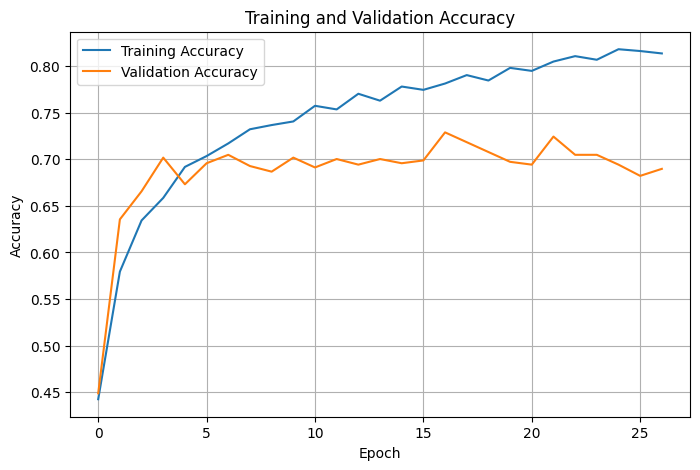

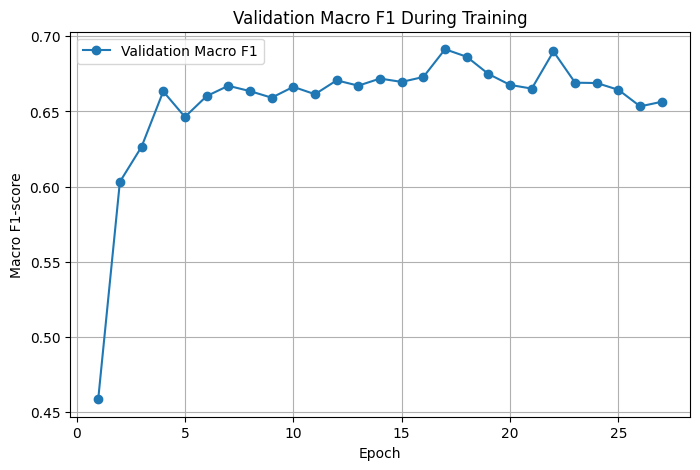

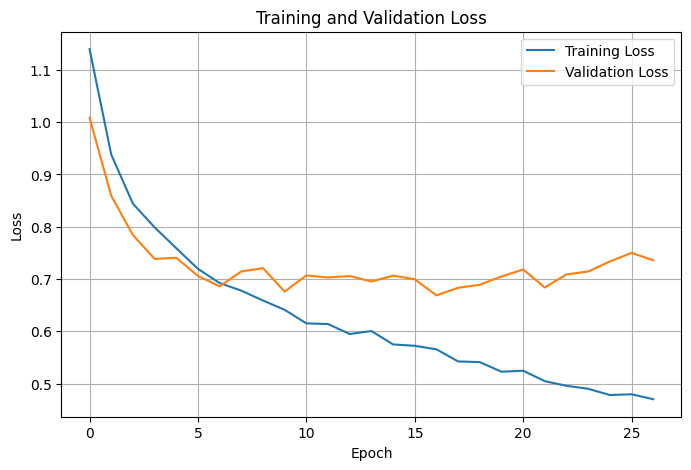

In [ ]:
HIDDEN_LAYERS = 2
HIDDEN_UNITS = 64
ACTIVATION = 'relu'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = True
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history1 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history1, macro_f1_callback)

Model 2

Hidden Layers 2->1

Epoch 1/50
71/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3341 - loss: 1.2388 - val_macro_f1: 0.6098
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4638 - loss: 1.0754 - val_accuracy: 0.6792 - val_loss: 0.8432 - val_macro_f1: 0.6098
Epoch 2/50
77/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6348 - loss: 0.8669 - val_macro_f1: 0.6330
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6308 - loss: 0.8558 - val_accuracy: 0.6777 - val_loss: 0.7929 - val_macro_f1: 0.6330
Epoch 3/50
76/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6815 - loss: 0.7962 - val_macro_f1: 0.6310
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6806 - loss: 0.7893 - val_accuracy: 0.6687 - val_loss: 0.7563 - val_macro_f1: 0.6310
Epoch 4/50
90/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7070 - loss: 0.7457 - val_macro_f1: 0.6571
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7083 - loss: 0.7396 - val_accuracy: 0.6943 - val_loss: 0.7193 - val_macro_f1: 0.6571
Epoch 5/50
73/97 ━━━

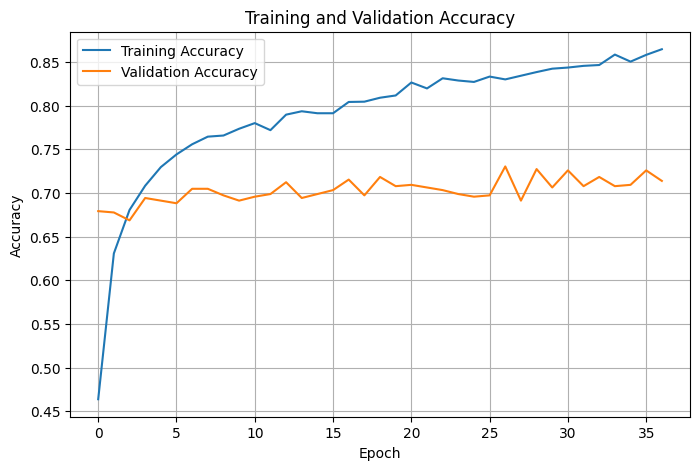

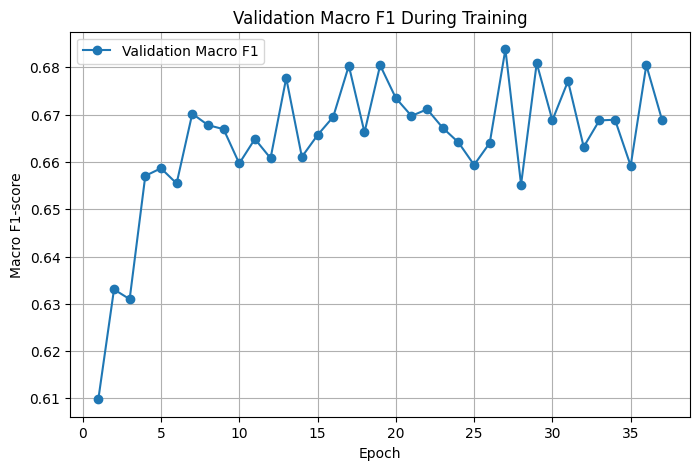

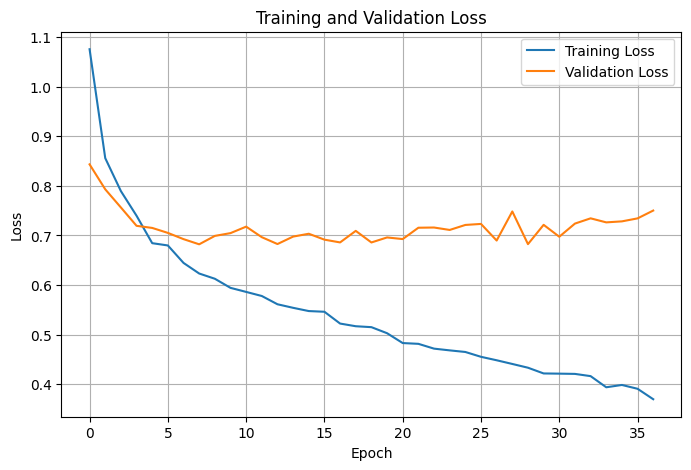

In [ ]:
HIDDEN_LAYERS = 1
HIDDEN_UNITS = 64
ACTIVATION = 'relu'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = True
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history2 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history2, macro_f1_callback)

Model 3

Hidden Layers = 2

Hidden Units 64 -> 32

Epoch 1/50
72/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.2907 - loss: 1.3500 - val_macro_f1: 0.4708
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.3592 - loss: 1.2237 - val_accuracy: 0.5090 - val_loss: 1.0036 - val_macro_f1: 0.4708
Epoch 2/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5278 - loss: 0.9924 - val_macro_f1: 0.5719
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5417 - loss: 0.9881 - val_accuracy: 0.6476 - val_loss: 0.8454 - val_macro_f1: 0.5719
Epoch 3/50
96/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5843 - loss: 0.9032 - val_macro_f1: 0.6006
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5927 - loss: 0.8997 - val_accuracy: 0.6506 - val_loss: 0.8060 - val_macro_f1: 0.6006
Epoch 4/50
67/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6345 - loss: 0.8362 - val_macro_f1: 0.6199
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6431 - loss: 0.8306 - val_accuracy: 0.6702 - val_loss: 0.7642 - val_macro_f1: 0.6199
Epoch 5/50
96/97 ━━━

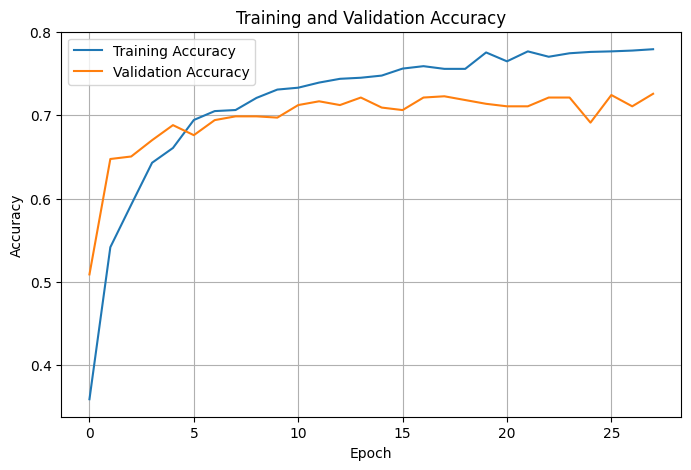

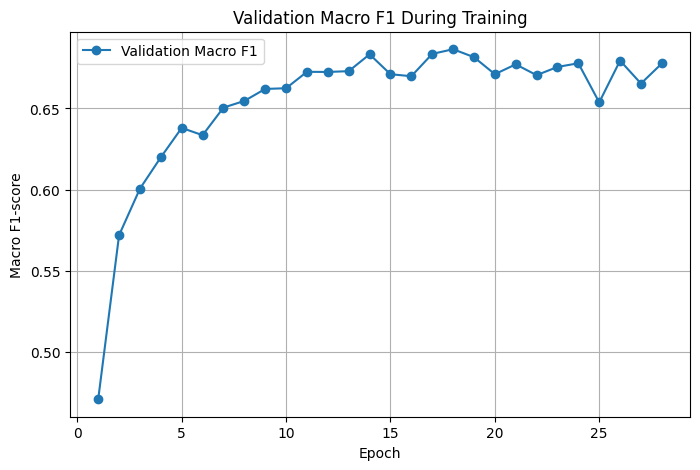

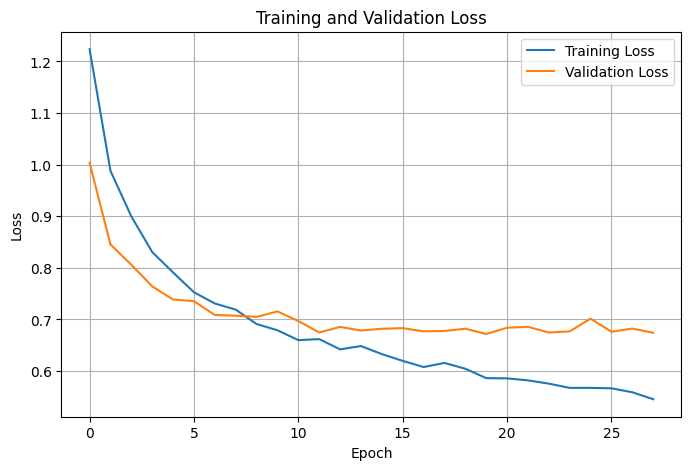

In [ ]:
HIDDEN_LAYERS = 2
HIDDEN_UNITS = 32
ACTIVATION = 'relu'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = True
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history3 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history3, macro_f1_callback)

Model 4

Hidden Units: 32

Activation Function: 'relu' -> 'tanh'

Epoch 1/50
94/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3845 - loss: 1.2014 - val_macro_f1: 0.5454
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.4483 - loss: 1.1078 - val_accuracy: 0.6039 - val_loss: 0.8874 - val_macro_f1: 0.5454
Epoch 2/50
86/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5809 - loss: 0.9268 - val_macro_f1: 0.6302
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6056 - loss: 0.9087 - val_accuracy: 0.6852 - val_loss: 0.7573 - val_macro_f1: 0.6302
Epoch 3/50
88/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6659 - loss: 0.8182 - val_macro_f1: 0.6443
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6705 - loss: 0.8168 - val_accuracy: 0.6867 - val_loss: 0.7339 - val_macro_f1: 0.6443
Epoch 4/50
83/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6955 - loss: 0.7716 - val_macro_f1: 0.6452
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6961 - loss: 0.7797 - val_accuracy: 0.6928 - val_loss: 0.6988 - val_macro_f1: 0.6452
Epoch 5/50
83/97 ━━

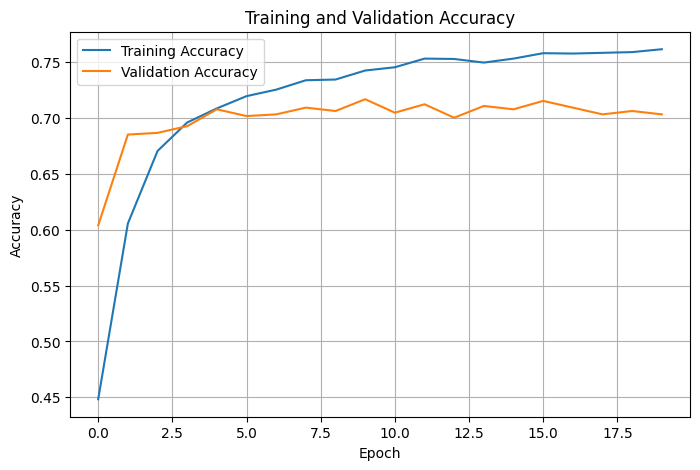

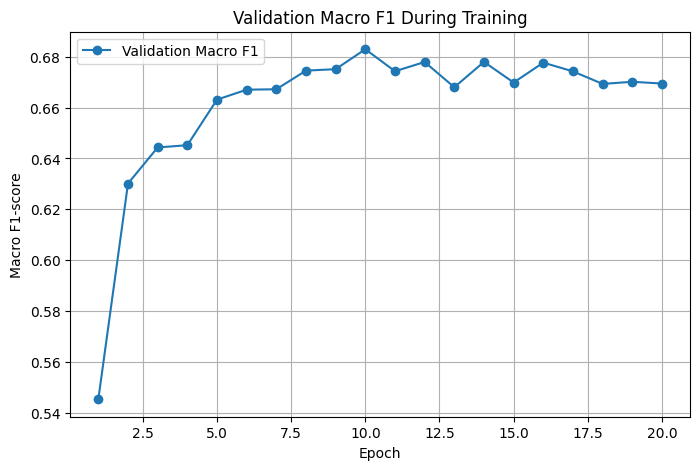

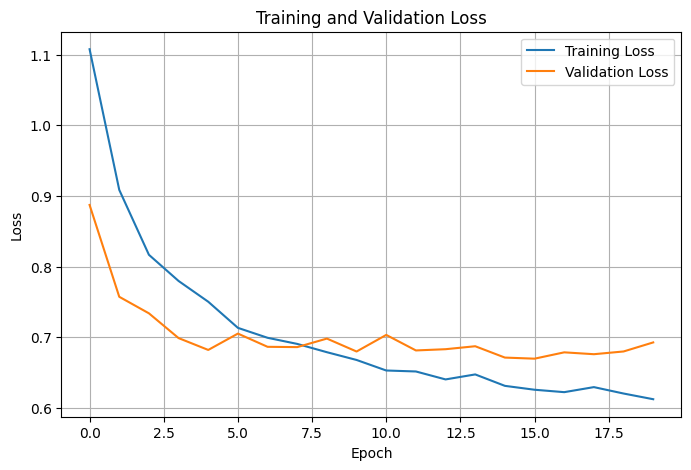

In [ ]:
HIDDEN_LAYERS = 2
HIDDEN_UNITS = 32
ACTIVATION = 'tanh'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = True
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history4 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history4, macro_f1_callback)

Model 5

ACTIVATION = tanh

Optimizer: Adam -> SGD

Epoch 1/50
73/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3013 - loss: 1.3591 - val_macro_f1: 0.2834
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3065 - loss: 1.3425 - val_accuracy: 0.2937 - val_loss: 1.2097 - val_macro_f1: 0.2834
Epoch 2/50
69/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3391 - loss: 1.2698 - val_macro_f1: 0.3748
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3437 - loss: 1.2482 - val_accuracy: 0.4081 - val_loss: 1.1113 - val_macro_f1: 0.3748
Epoch 3/50
84/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3881 - loss: 1.1831 - val_macro_f1: 0.3774
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3902 - loss: 1.1795 - val_accuracy: 0.3991 - val_loss: 1.0958 - val_macro_f1: 0.3774
Epoch 4/50
95/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4011 - loss: 1.1468 - val_macro_f1: 0.4356
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4034 - loss: 1.1636 - val_accuracy: 0.4714 - val_loss: 1.0397 - val_macro_f1: 0.4356
Epoch 5/50
72/97 ━━━

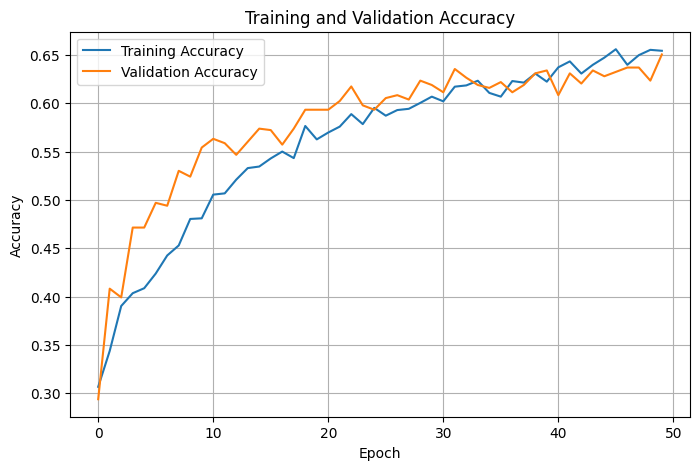

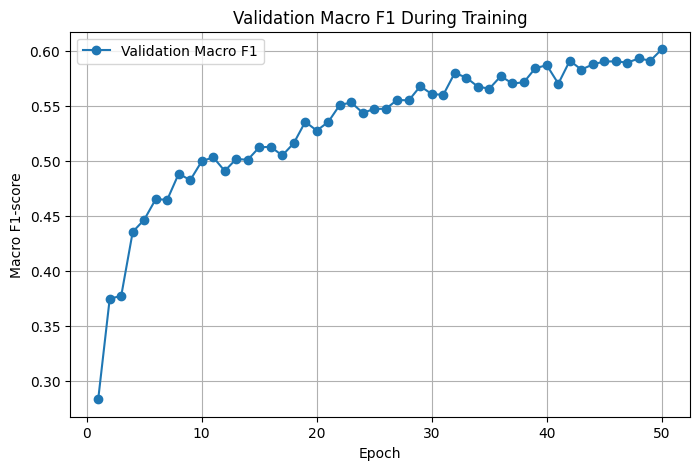

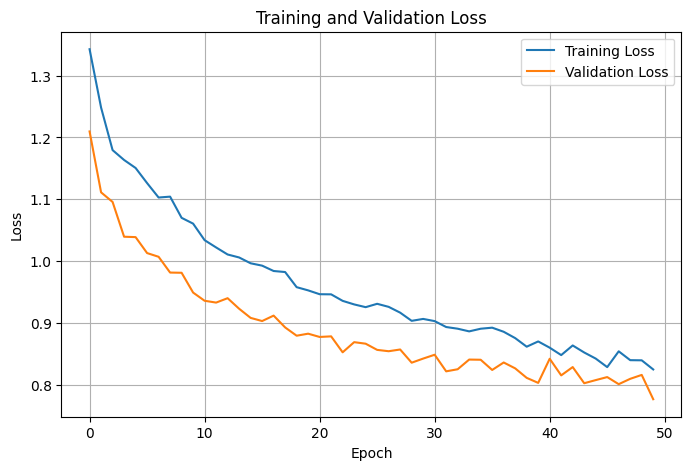

In [ ]:
HIDDEN_LAYERS = 2
HIDDEN_UNITS = 32
ACTIVATION = 'tanh'
OPTIMIZER = 'sgd'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = True
EARLY_STOPPING =True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history5 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    class_weight=class_weights,
    batch_size=BATCH_SIZE,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history5, macro_f1_callback)

Model 6

Learning Rate: 0.001 -> 0.0005

Epoch 1/50
83/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3403 - loss: 1.2739 - val_macro_f1: 0.4580
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.3902 - loss: 1.1927 - val_accuracy: 0.5151 - val_loss: 0.9860 - val_macro_f1: 0.4580
Epoch 2/50
84/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4973 - loss: 1.0319 - val_macro_f1: 0.5661
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5216 - loss: 1.0125 - val_accuracy: 0.6280 - val_loss: 0.8686 - val_macro_f1: 0.5661
Epoch 3/50
87/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5897 - loss: 0.9283 - val_macro_f1: 0.5901
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5901 - loss: 0.9225 - val_accuracy: 0.6581 - val_loss: 0.8053 - val_macro_f1: 0.5901
Epoch 4/50
80/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6277 - loss: 0.8659 - val_macro_f1: 0.6114
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6266 - loss: 0.8765 - val_accuracy: 0.6732 - val_loss: 0.7551 - val_macro_f1: 0.6114
Epoch 5/50
90/97 ━━━

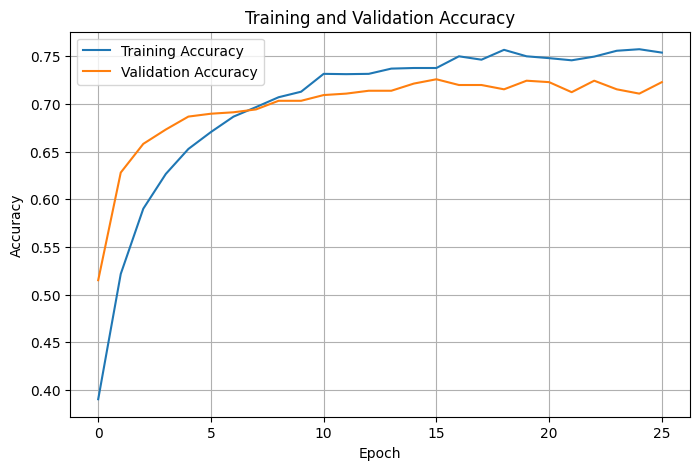

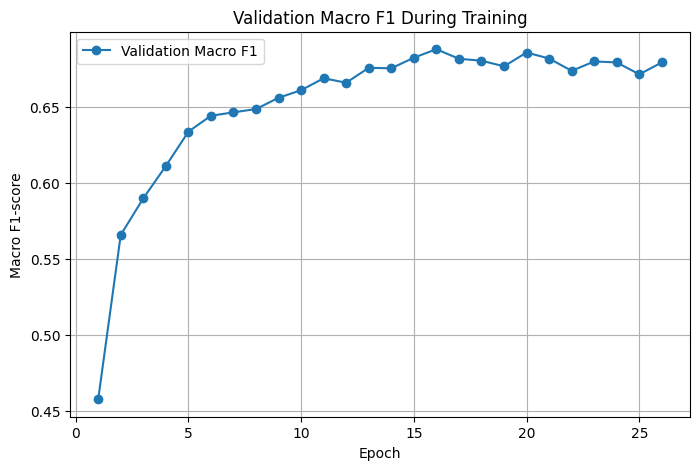

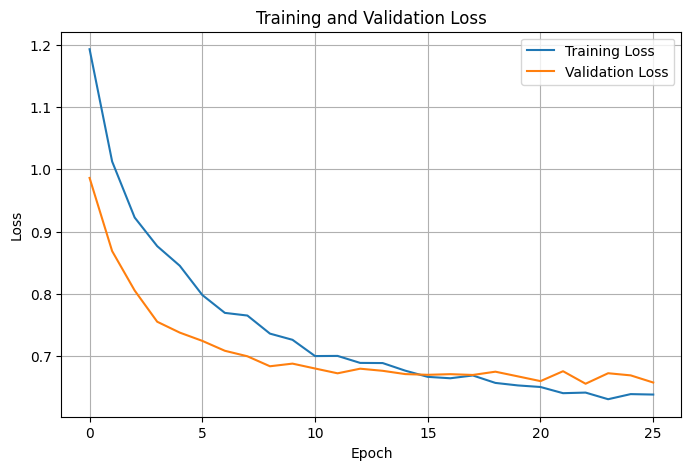

In [ ]:
HIDDEN_LAYERS = 2
HIDDEN_UNITS = 32
ACTIVATION = 'tanh'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.0005
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = True
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history6 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    class_weight=class_weights,
    batch_size=BATCH_SIZE,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history6, macro_f1_callback)

Model 7

Batch Size: 32 -> 16

Epoch 1/50
182/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3982 - loss: 1.1871 - val_macro_f1: 0.5781
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4839 - loss: 1.0708 - val_accuracy: 0.6099 - val_loss: 0.8601 - val_macro_f1: 0.5781
Epoch 2/50
172/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5970 - loss: 0.9072 - val_macro_f1: 0.6301
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6218 - loss: 0.8918 - val_accuracy: 0.6657 - val_loss: 0.7748 - val_macro_f1: 0.6301
Epoch 3/50
166/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6795 - loss: 0.7957 - val_macro_f1: 0.6335
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6731 - loss: 0.8015 - val_accuracy: 0.6747 - val_loss: 0.7373 - val_macro_f1: 0.6335
Epoch 4/50
169/194 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6939 - loss: 0.7641 - val_macro_f1: 0.6556
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6919 - loss: 0.7652 - val_accuracy: 0.6973 - val_loss: 0.7143 - val_macro_f1: 0.6556
Epoc

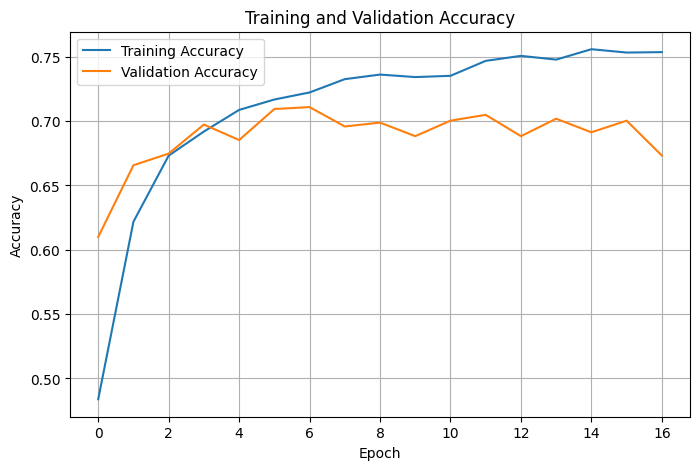

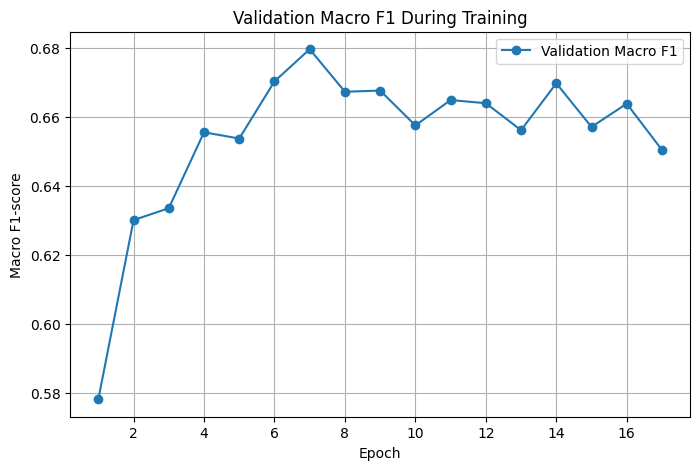

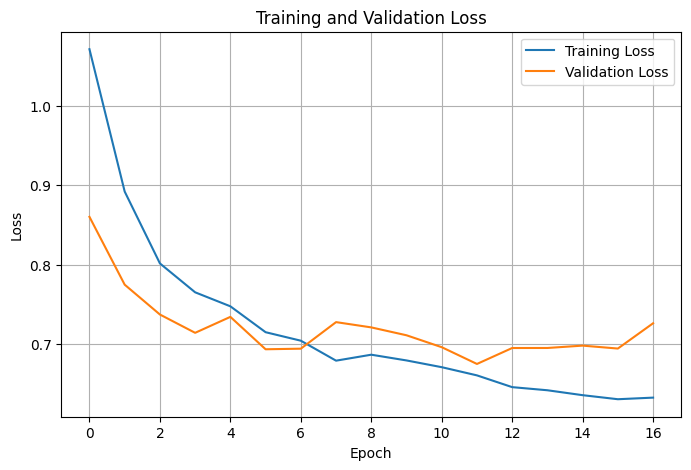

In [ ]:
HIDDEN_LAYERS = 2
HIDDEN_UNITS = 32
ACTIVATION = 'tanh'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 16
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = True
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history7 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    class_weight=class_weights,
    batch_size=BATCH_SIZE,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history7, macro_f1_callback)

Model 8

Dropout: 0.2 -> 0.4

Epoch 1/50
89/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3481 - loss: 1.3289 - val_macro_f1: 0.5015
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.3840 - loss: 1.2666 - val_accuracy: 0.5663 - val_loss: 0.9299 - val_macro_f1: 0.5015
Epoch 2/50
86/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4951 - loss: 1.0731 - val_macro_f1: 0.5975
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5145 - loss: 1.0435 - val_accuracy: 0.6566 - val_loss: 0.8186 - val_macro_f1: 0.5975
Epoch 3/50
88/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5700 - loss: 0.9541 - val_macro_f1: 0.6105
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5882 - loss: 0.9380 - val_accuracy: 0.6732 - val_loss: 0.7592 - val_macro_f1: 0.6105
Epoch 4/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6163 - loss: 0.8772 - val_macro_f1: 0.6407
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6286 - loss: 0.8838 - val_accuracy: 0.6958 - val_loss: 0.7337 - val_macro_f1: 0.6407
Epoch 5/50
86/97 ━━━

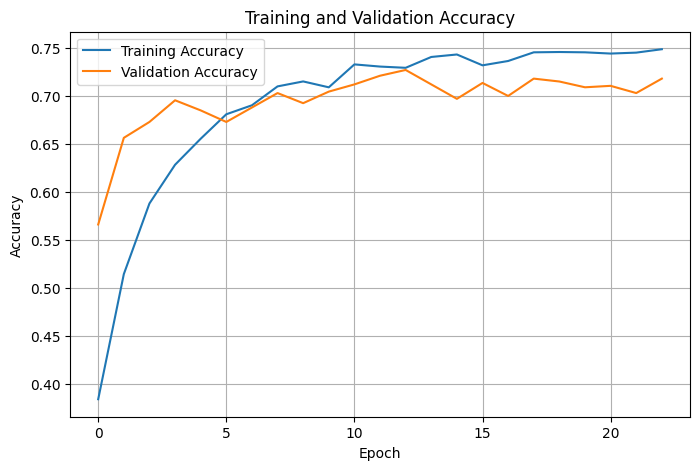

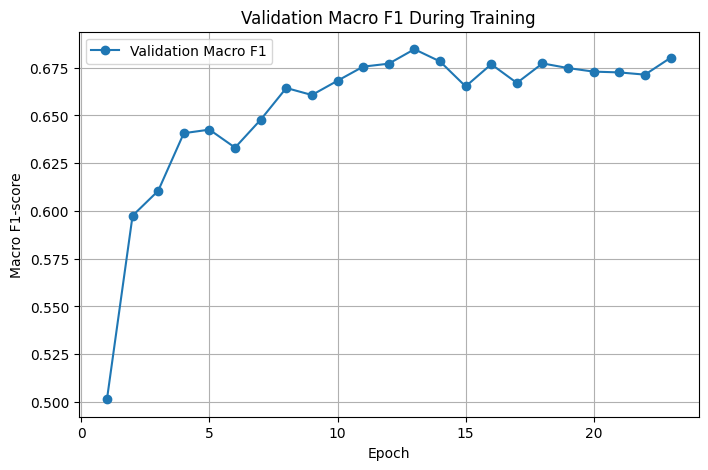

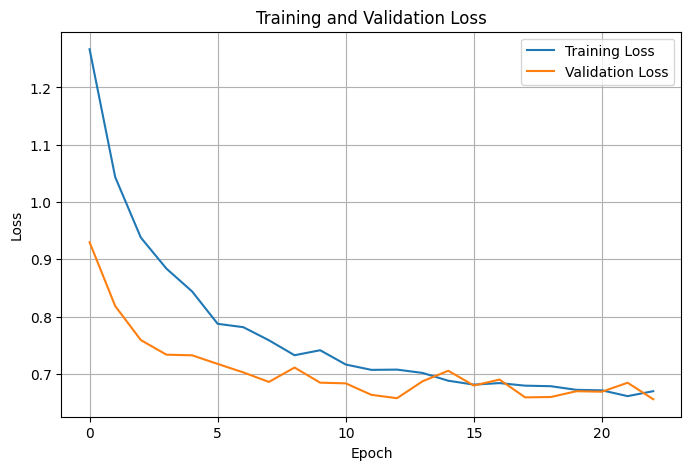

In [ ]:
HIDDEN_LAYERS = 2
HIDDEN_UNITS = 32
ACTIVATION = 'tanh'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.4
BATCH_NORMALIZATION = True
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history8 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    class_weight=class_weights,
    batch_size=BATCH_SIZE,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history8, macro_f1_callback)

Model 9

Batch Normalization: False

Epoch 1/50
77/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3377 - loss: 1.2931 - val_macro_f1: 0.5286
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4289 - loss: 1.1613 - val_accuracy: 0.5843 - val_loss: 0.9175 - val_macro_f1: 0.5286
Epoch 2/50
89/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5854 - loss: 0.9371 - val_macro_f1: 0.6041
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5914 - loss: 0.9319 - val_accuracy: 0.6491 - val_loss: 0.8165 - val_macro_f1: 0.6041
Epoch 3/50
94/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6593 - loss: 0.8325 - val_macro_f1: 0.6230
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6531 - loss: 0.8219 - val_accuracy: 0.6566 - val_loss: 0.7720 - val_macro_f1: 0.6230
Epoch 4/50
70/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6819 - loss: 0.7685 - val_macro_f1: 0.6472
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6757 - loss: 0.7881 - val_accuracy: 0.6898 - val_loss: 0.7228 - val_macro_f1: 0.6472
Epoch 5/50
68/97 ━━━

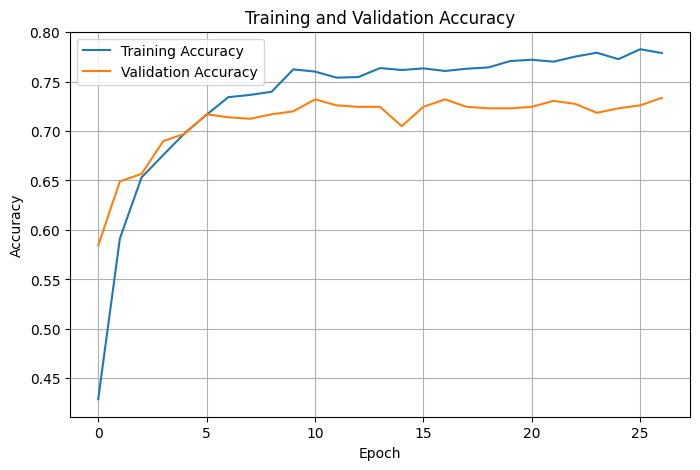

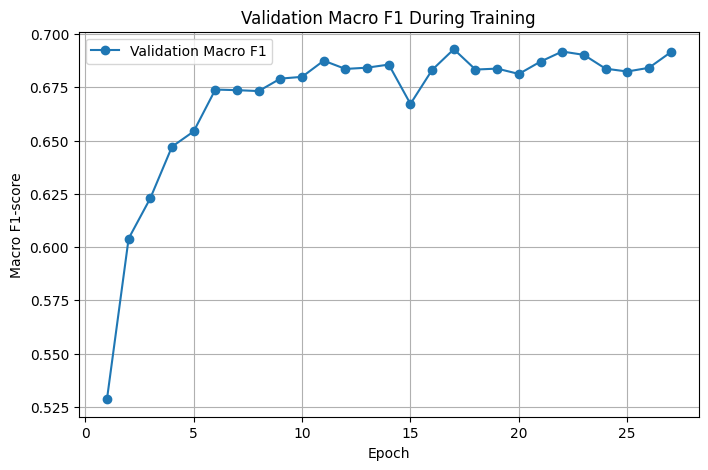

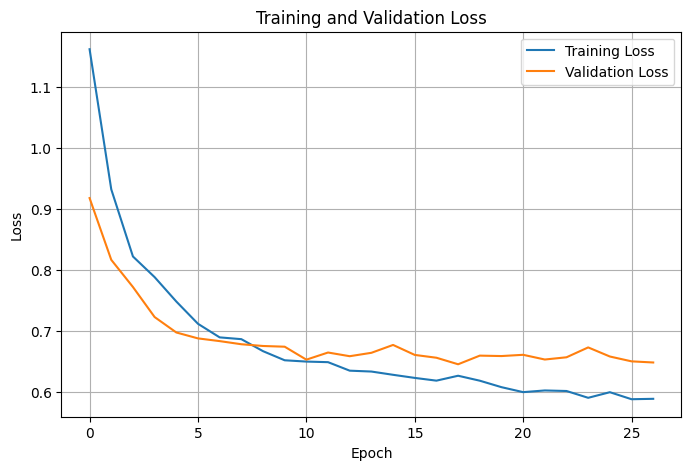

In [ ]:
HIDDEN_LAYERS = 2
HIDDEN_UNITS = 32
ACTIVATION = 'tanh'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = False
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history9 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    class_weight=class_weights,
    batch_size=BATCH_SIZE,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)


# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history9, macro_f1_callback)

Model 10

Batch Normalization: False

Weight Initialization: 'He' -> 'Xavier'

Epoch 1/50
87/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3714 - loss: 1.1821 - val_macro_f1: 0.5903
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4477 - loss: 1.0998 - val_accuracy: 0.6370 - val_loss: 0.8817 - val_macro_f1: 0.5903
Epoch 2/50
75/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5440 - loss: 0.9563 - val_macro_f1: 0.6380
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5788 - loss: 0.9269 - val_accuracy: 0.6762 - val_loss: 0.7897 - val_macro_f1: 0.6380
Epoch 3/50
68/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6404 - loss: 0.8282 - val_macro_f1: 0.6532
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6515 - loss: 0.8246 - val_accuracy: 0.6943 - val_loss: 0.7433 - val_macro_f1: 0.6532
Epoch 4/50
94/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6837 - loss: 0.7869 - val_macro_f1: 0.6631
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6864 - loss: 0.7770 - val_accuracy: 0.7093 - val_loss: 0.7064 - val_macro_f1: 0.6631
Epoch 5/50
69/97 ━━━

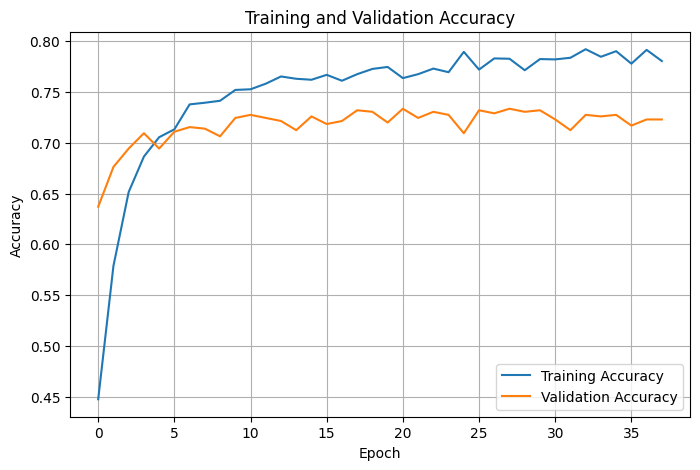

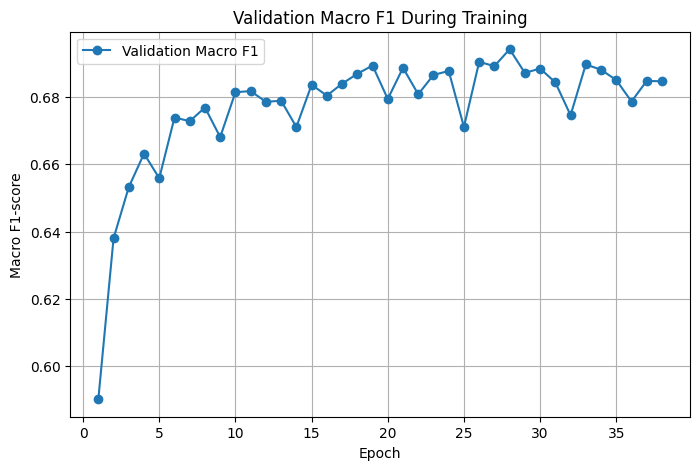

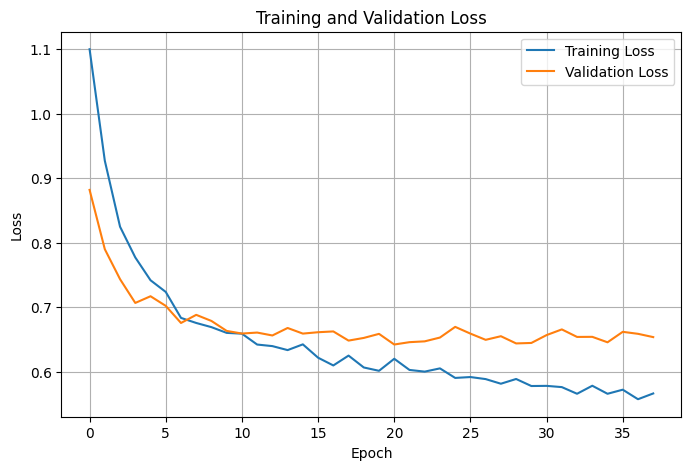

In [ ]:
HIDDEN_LAYERS = 2
HIDDEN_UNITS = 32
ACTIVATION = 'tanh'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = False
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'xavier'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history10 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    class_weight=class_weights,
    batch_size=BATCH_SIZE,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history10, macro_f1_callback)

Model 11

Weight Initialization = 'Xavier'

Loss Function: 'Cross Entropy' -> 'Focal Loss'

Epoch 1/50
78/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4188 - loss: 0.1591 - val_macro_f1: 0.4823
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5068 - loss: 0.1313 - val_accuracy: 0.6521 - val_loss: 0.0866 - val_macro_f1: 0.4823
Epoch 2/50
80/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5703 - loss: 0.1070 - val_macro_f1: 0.5521
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6101 - loss: 0.1008 - val_accuracy: 0.6958 - val_loss: 0.0779 - val_macro_f1: 0.5521
Epoch 3/50
93/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6771 - loss: 0.0868 - val_macro_f1: 0.5947
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6754 - loss: 0.0861 - val_accuracy: 0.7274 - val_loss: 0.0735 - val_macro_f1: 0.5947
Epoch 4/50
92/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7110 - loss: 0.0797 - val_macro_f1: 0.6039
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7135 - loss: 0.0776 - val_accuracy: 0.7274 - val_loss: 0.0713 - val_macro_f1: 0.6039
Epoch 5/50
71/97 ━━━

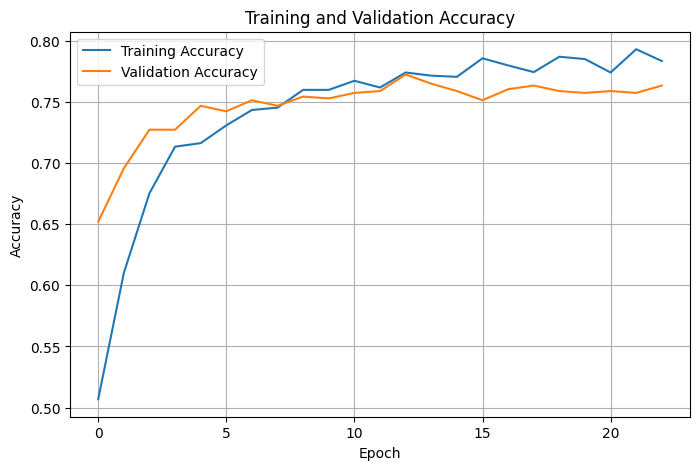

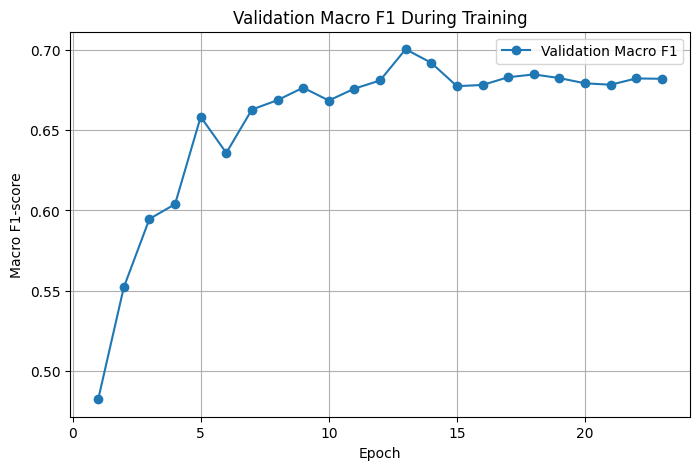

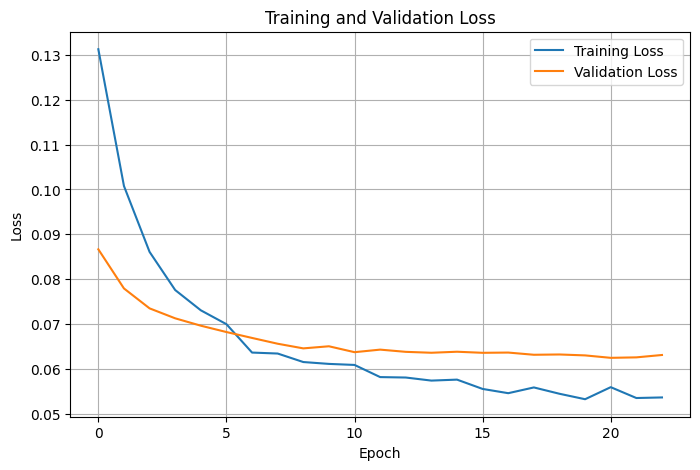

In [ ]:
# convert labels into one-hot encoded
y2_train = tf.keras.utils.to_categorical(y_train, num_classes=3)
y2_val = tf.keras.utils.to_categorical(y_val, num_classes=3)
# define focal loss
def categorical_focal_loss(gamma=2.0, alpha=0.25):
    def loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)

        cross_entropy = -y_true * tf.math.log(y_pred)
        focal_weight = alpha * tf.pow(1.0 - y_pred, gamma)

        return tf.reduce_sum(focal_weight * cross_entropy, axis=-1)

    return loss

HIDDEN_LAYERS = 2
HIDDEN_UNITS = 32
ACTIVATION = 'tanh'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = False
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'xavier'
LOSS_FUNCTION = categorical_focal_loss(gamma=2.0, alpha=0.25)
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history11 = model.fit(
    x_train.astype('float32'),
    y2_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y2_val.astype('int32')
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history11, macro_f1_callback)

Model 12

Hidden Layers: 2 -> 1

Batch Normalization: False

Epoch 1/50
72/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3455 - loss: 1.9099 - val_macro_f1: 0.6041
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4512 - loss: 1.4091 - val_accuracy: 0.6611 - val_loss: 0.8336 - val_macro_f1: 0.6041
Epoch 2/50
70/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5961 - loss: 0.9779 - val_macro_f1: 0.6237
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5966 - loss: 0.9656 - val_accuracy: 0.6521 - val_loss: 0.8160 - val_macro_f1: 0.6237
Epoch 3/50
70/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6238 - loss: 0.8798 - val_macro_f1: 0.6555
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6402 - loss: 0.8559 - val_accuracy: 0.6883 - val_loss: 0.7570 - val_macro_f1: 0.6555
Epoch 4/50
94/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6927 - loss: 0.7916 - val_macro_f1: 0.6465
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6925 - loss: 0.7731 - val_accuracy: 0.6792 - val_loss: 0.7423 - val_macro_f1: 0.6465
Epoch 5/50
68/97 ━━━

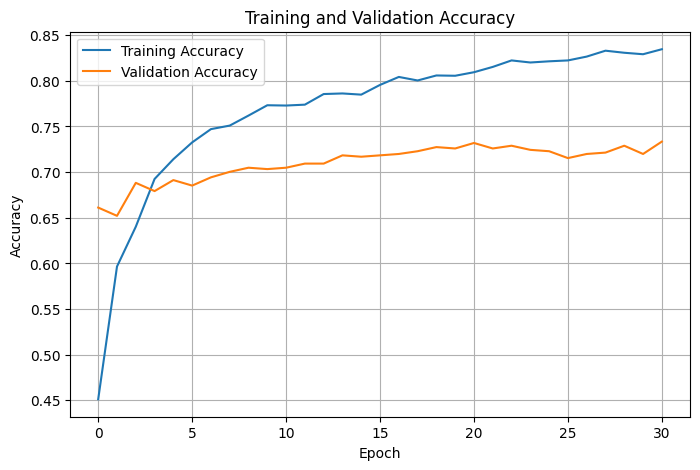

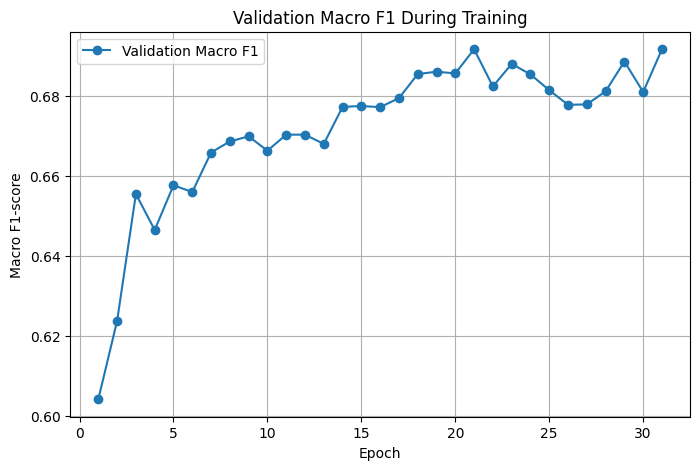

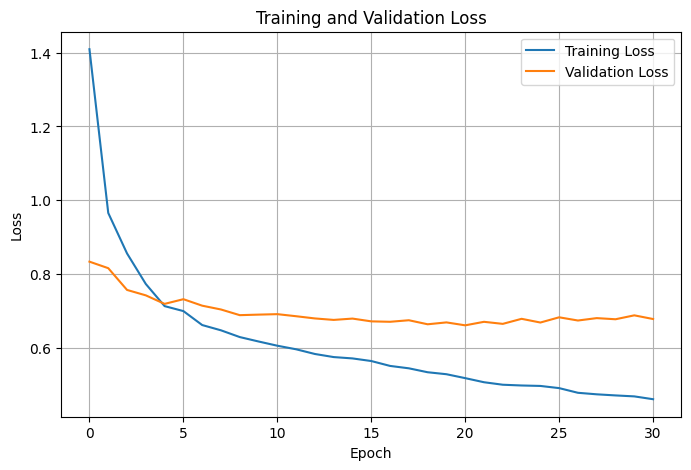

In [ ]:
HIDDEN_LAYERS = 1
HIDDEN_UNITS = 64
ACTIVATION = 'relu'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = False
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history12 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history12, macro_f1_callback)

Model 13

Hidden Units: 64 -> 32

Epoch 1/50
61/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3634 - loss: 1.3701 - val_macro_f1: 0.5454
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4474 - loss: 1.1767 - val_accuracy: 0.5738 - val_loss: 0.9128 - val_macro_f1: 0.5454
Epoch 2/50
66/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5466 - loss: 0.9510 - val_macro_f1: 0.5876
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5753 - loss: 0.9170 - val_accuracy: 0.6114 - val_loss: 0.8553 - val_macro_f1: 0.5876
Epoch 3/50
63/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6271 - loss: 0.8367 - val_macro_f1: 0.6200
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6554 - loss: 0.8207 - val_accuracy: 0.6551 - val_loss: 0.7904 - val_macro_f1: 0.6200
Epoch 4/50
96/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6727 - loss: 0.7781 - val_macro_f1: 0.6314
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6828 - loss: 0.7660 - val_accuracy: 0.6657 - val_loss: 0.7628 - val_macro_f1: 0.6314
Epoch 5/50
72/97 ━━━

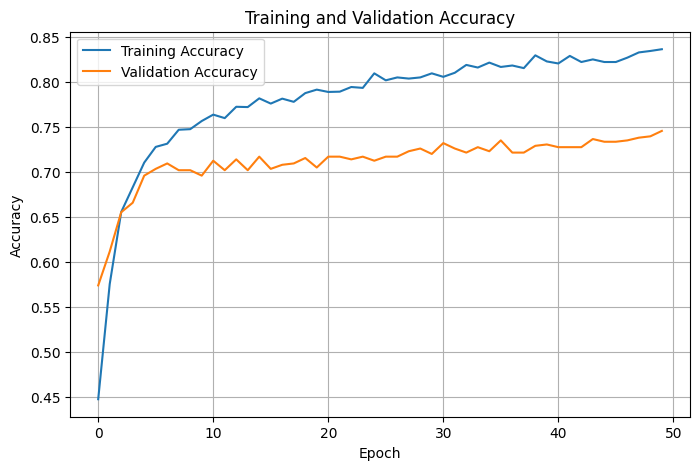

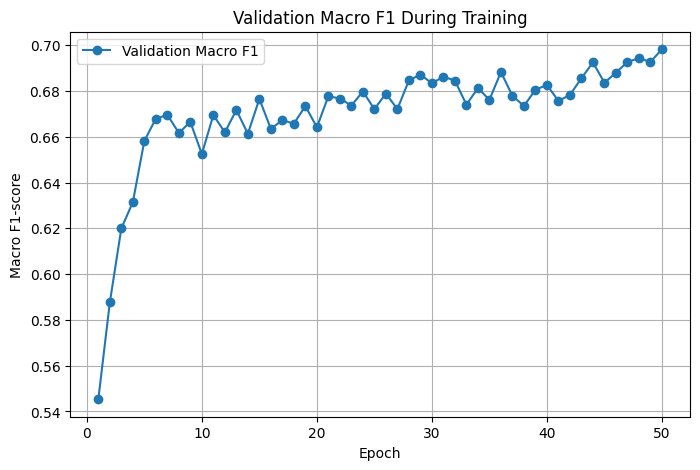

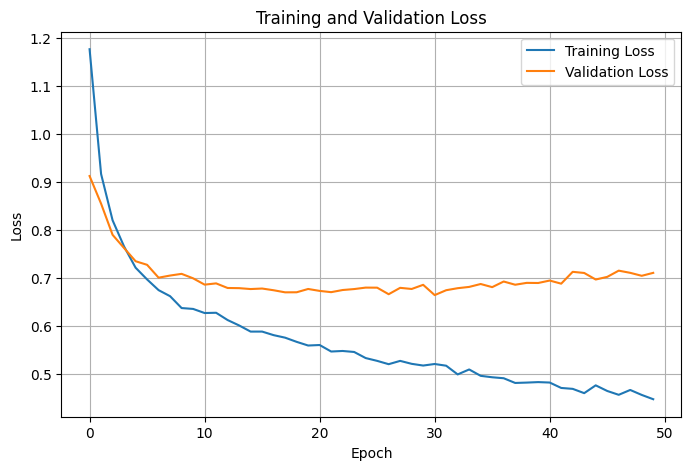

In [ ]:
HIDDEN_LAYERS = 1
HIDDEN_UNITS = 32
ACTIVATION = 'relu'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = False
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history13 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history13, macro_f1_callback)

Model 14

Hidden Layers: 3

Hidden Units: 64

Epoch 1/50
77/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3849 - loss: 1.6895 - val_macro_f1: 0.5352
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4115 - loss: 1.4236 - val_accuracy: 0.5753 - val_loss: 0.9584 - val_macro_f1: 0.5352
Epoch 2/50
83/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4806 - loss: 1.1003 - val_macro_f1: 0.5988
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5226 - loss: 1.0559 - val_accuracy: 0.6506 - val_loss: 0.8663 - val_macro_f1: 0.5988
Epoch 3/50
72/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5891 - loss: 0.9654 - val_macro_f1: 0.6233
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5972 - loss: 0.9460 - val_accuracy: 0.6762 - val_loss: 0.8063 - val_macro_f1: 0.6233
Epoch 4/50
74/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6164 - loss: 0.8782 - val_macro_f1: 0.6275
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6386 - loss: 0.8557 - val_accuracy: 0.6657 - val_loss: 0.7938 - val_macro_f1: 0.6275
Epoch 5/50
91/97 ━━━

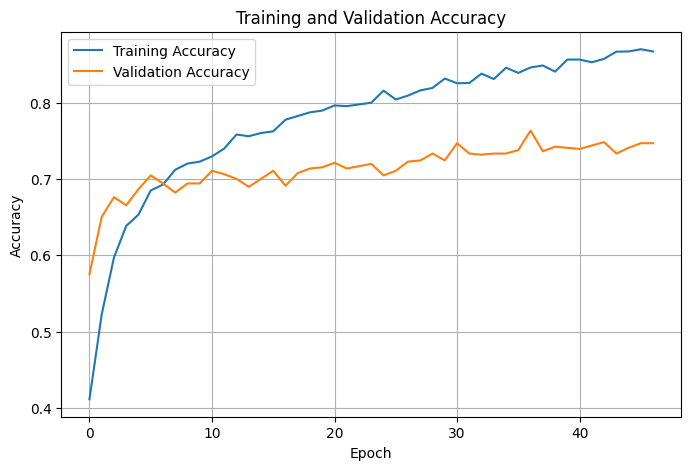

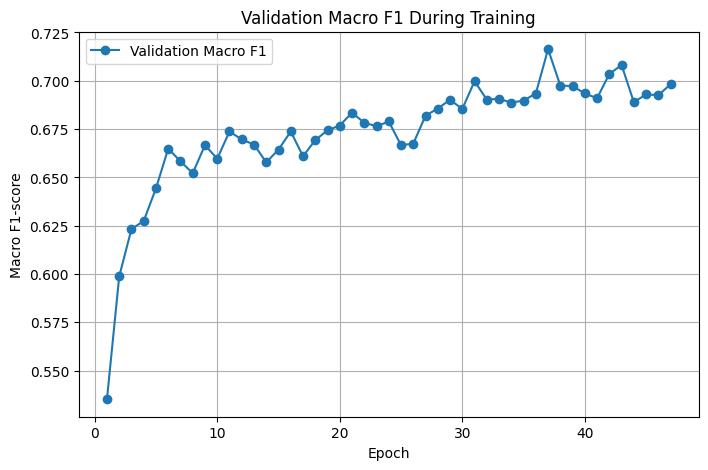

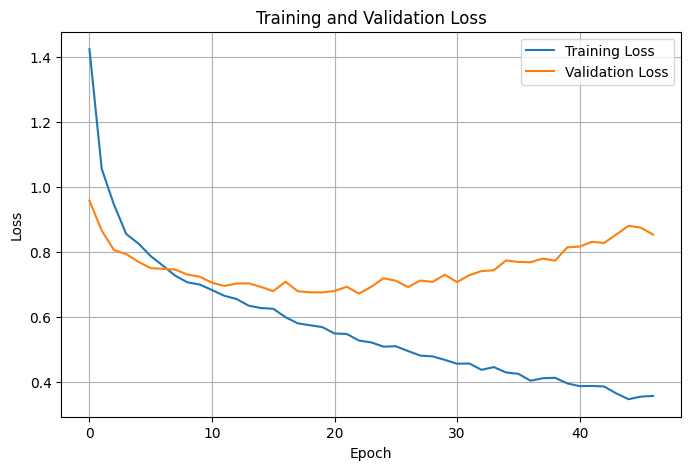

In [ ]:
HIDDEN_LAYERS = 3
HIDDEN_UNITS = 64
ACTIVATION = 'relu'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = False
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history14 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history14, macro_f1_callback)

Model 15

Loss Function: Focal Loss

Epoch 1/50
81/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3844 - loss: 0.3167 - val_macro_f1: 0.4603
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.4015 - loss: 0.2370 - val_accuracy: 0.4759 - val_loss: 0.1098 - val_macro_f1: 0.4603
Epoch 2/50
94/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4611 - loss: 0.1428 - val_macro_f1: 0.5487
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4787 - loss: 0.1335 - val_accuracy: 0.5949 - val_loss: 0.0966 - val_macro_f1: 0.5487
Epoch 3/50
90/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5273 - loss: 0.1145 - val_macro_f1: 0.5876
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5407 - loss: 0.1118 - val_accuracy: 0.6386 - val_loss: 0.0893 - val_macro_f1: 0.5876
Epoch 4/50
78/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5525 - loss: 0.1027 - val_macro_f1: 0.6116
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5791 - loss: 0.0988 - val_accuracy: 0.6491 - val_loss: 0.0863 - val_macro_f1: 0.6116
Epoch 5/50
77/97 ━━━

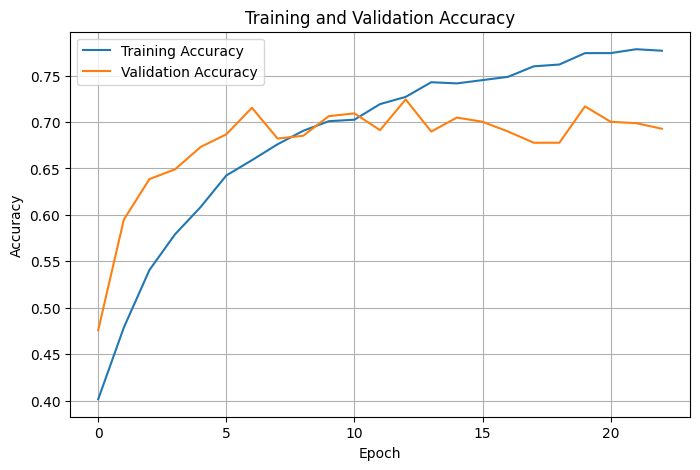

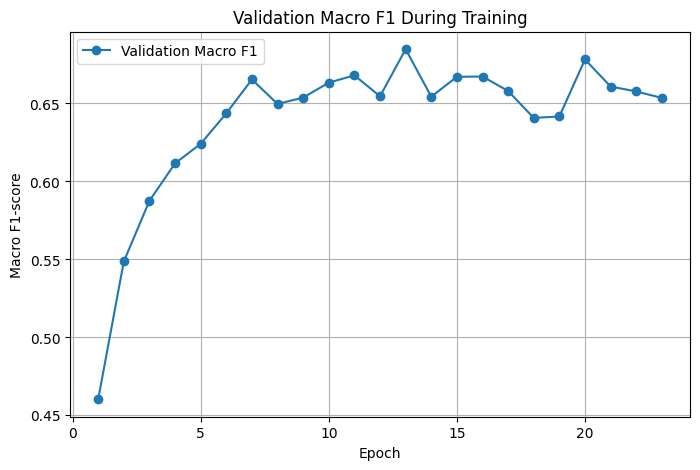

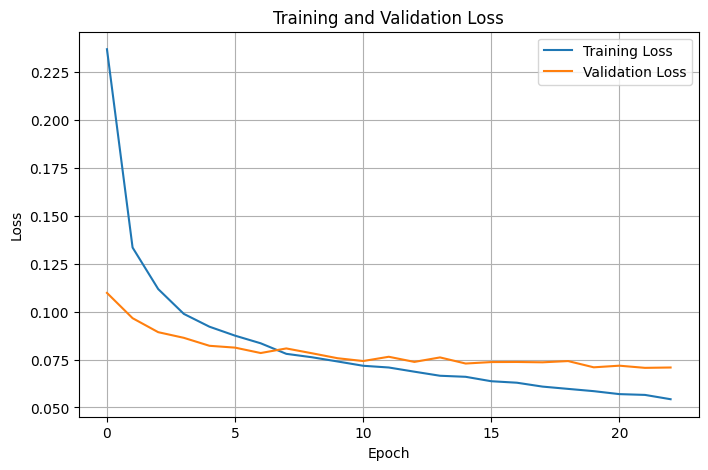

In [ ]:
HIDDEN_LAYERS = 3
HIDDEN_UNITS = 64
ACTIVATION = 'relu'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = False
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = categorical_focal_loss(gamma=2.0, alpha=0.25)
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history15= model.fit(
    x_train.astype('float32'),
    y2_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y2_val.astype('int32')
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history15, macro_f1_callback)

Model 16

Dropout: 0.0

Epoch 1/50
65/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4450 - loss: 1.2955 - val_macro_f1: 0.5896
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5504 - loss: 1.0218 - val_accuracy: 0.6235 - val_loss: 0.8608 - val_macro_f1: 0.5896
Epoch 2/50
67/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6483 - loss: 0.8114 - val_macro_f1: 0.6132
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6699 - loss: 0.7864 - val_accuracy: 0.6536 - val_loss: 0.7877 - val_macro_f1: 0.6132
Epoch 3/50
92/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7025 - loss: 0.7122 - val_macro_f1: 0.6250
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7132 - loss: 0.6991 - val_accuracy: 0.6747 - val_loss: 0.7628 - val_macro_f1: 0.6250
Epoch 4/50
95/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7420 - loss: 0.6525 - val_macro_f1: 0.6366
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7384 - loss: 0.6470 - val_accuracy: 0.6822 - val_loss: 0.7493 - val_macro_f1: 0.6366
Epoch 5/50
68/97 ━━━

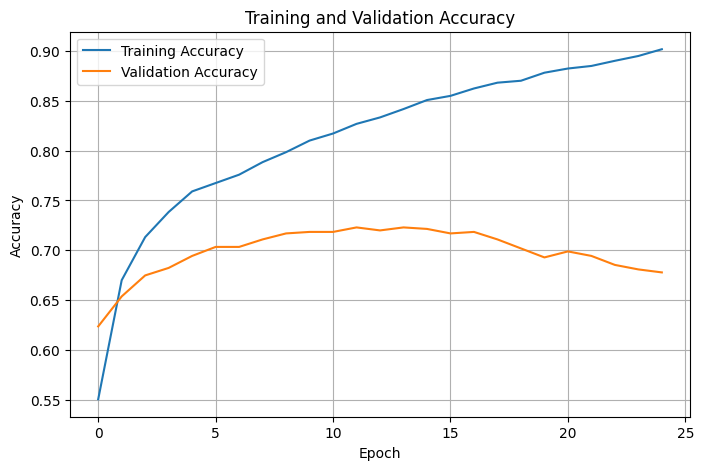

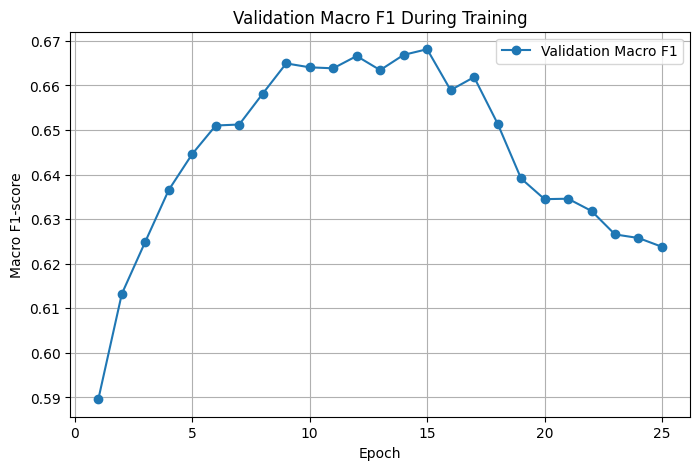

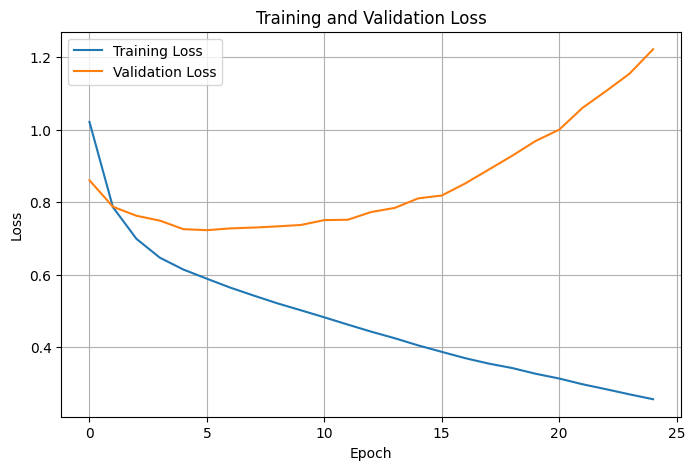

In [ ]:
HIDDEN_LAYERS = 3
HIDDEN_UNITS = 64
ACTIVATION = 'relu'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.0
BATCH_NORMALIZATION = False
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history16 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history16, macro_f1_callback)

Model 17

Dropout: 0.1

Epoch 1/50
76/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4084 - loss: 1.4529 - val_macro_f1: 0.5768
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.4800 - loss: 1.2200 - val_accuracy: 0.6280 - val_loss: 0.8802 - val_macro_f1: 0.5768
Epoch 2/50
92/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5892 - loss: 0.9376 - val_macro_f1: 0.5934
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6089 - loss: 0.9172 - val_accuracy: 0.6355 - val_loss: 0.8058 - val_macro_f1: 0.5934
Epoch 3/50
90/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6557 - loss: 0.8419 - val_macro_f1: 0.6242
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6563 - loss: 0.8396 - val_accuracy: 0.6717 - val_loss: 0.7633 - val_macro_f1: 0.6242
Epoch 4/50
91/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6783 - loss: 0.7768 - val_macro_f1: 0.6421
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6812 - loss: 0.7647 - val_accuracy: 0.6717 - val_loss: 0.7625 - val_macro_f1: 0.6421
Epoch 5/50
76/97 ━━━

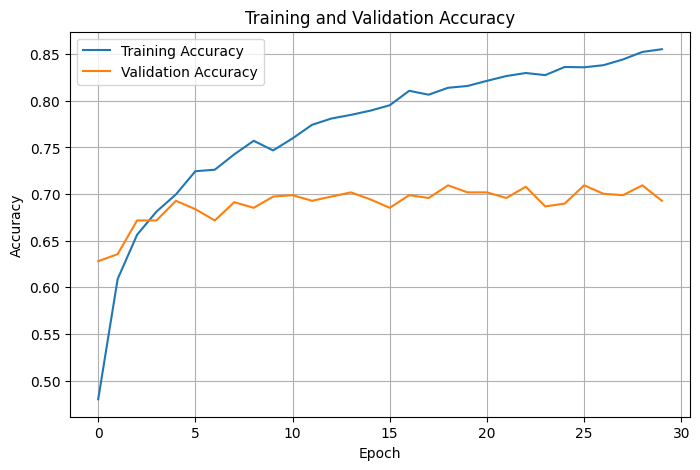

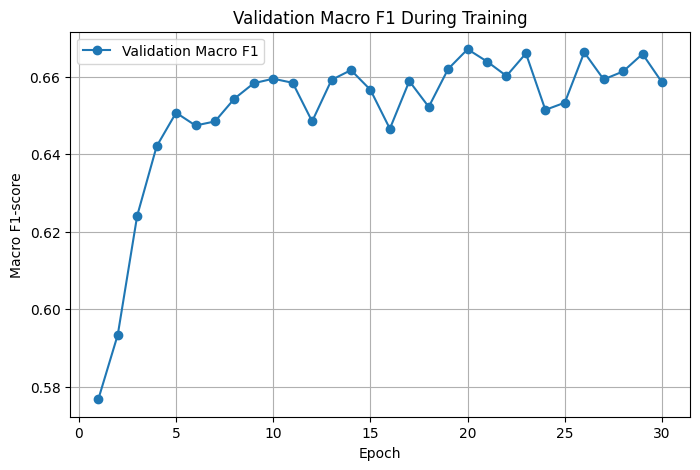

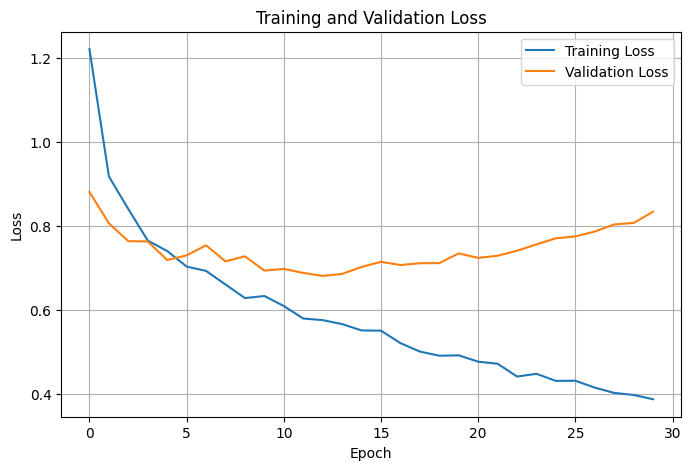

In [ ]:
HIDDEN_LAYERS = 3
HIDDEN_UNITS = 64
ACTIVATION = 'relu'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.1
BATCH_NORMALIZATION = False
EARLY_STOPPING = True
PATIENCE = 10
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history17 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history17, macro_f1_callback)

Model 18

Hidden Layers: 3

Hidden Units: 64

Epoch: 100

Patience: 15

Epoch 1/50
95/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3893 - loss: 1.6448 - val_macro_f1: 0.5352
97/97 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4115 - loss: 1.4236 - val_accuracy: 0.5753 - val_loss: 0.9584 - val_macro_f1: 0.5352
Epoch 2/50
91/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4842 - loss: 1.0968 - val_macro_f1: 0.5988
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5226 - loss: 1.0559 - val_accuracy: 0.6506 - val_loss: 0.8663 - val_macro_f1: 0.5988
Epoch 3/50
90/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5902 - loss: 0.9615 - val_macro_f1: 0.6233
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5972 - loss: 0.9460 - val_accuracy: 0.6762 - val_loss: 0.8063 - val_macro_f1: 0.6233
Epoch 4/50
85/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6196 - loss: 0.8747 - val_macro_f1: 0.6275
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6386 - loss: 0.8557 - val_accuracy: 0.6657 - val_loss: 0.7938 - val_macro_f1: 0.6275
Epoch 5/50
78/97 ━━━

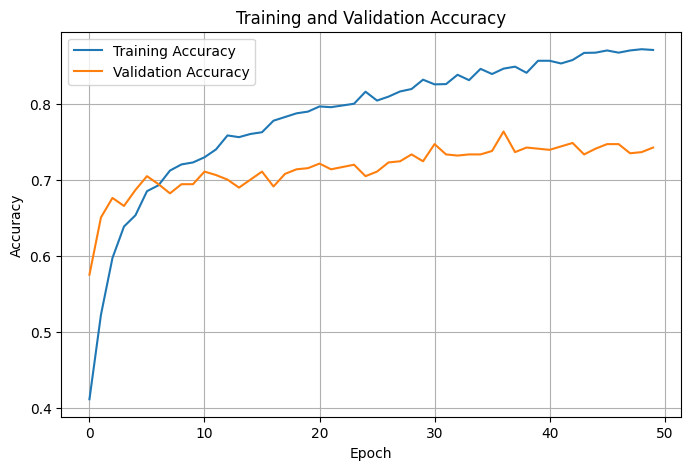

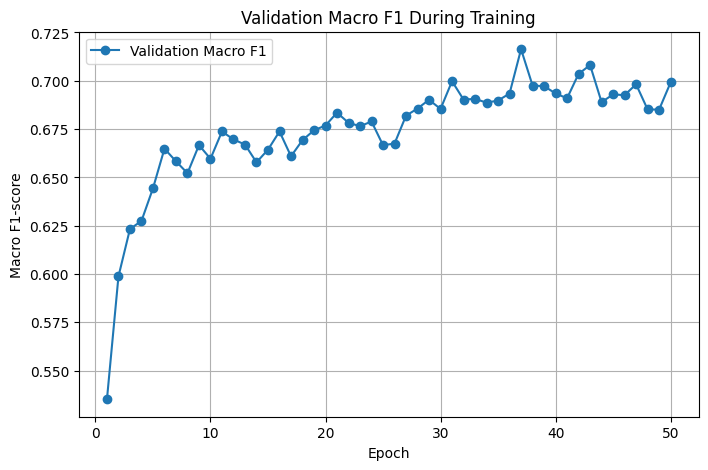

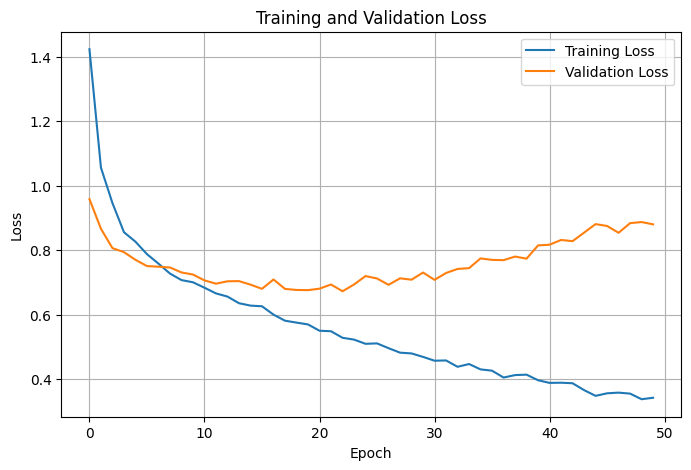

In [ ]:
HIDDEN_LAYERS = 3
HIDDEN_UNITS = 64
ACTIVATION = 'relu'
OPTIMIZER = 'adam'
LEARNING_RATE = 0.001
BATCH_SIZE = 32
DROPOUT_RATE = 0.2
BATCH_NORMALIZATION = False
EARLY_STOPPING = True
PATIENCE = 15
WEIGHT_INITIALIZATION = 'he'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCHS = 50

# create model
model = initialize_model()

# create F1 callback
macro_f1_callback = MacroF1Callback(x_val.astype('float32'), y_val.astype('int32'))

# Train
history18 = model.fit(
    x_train.astype('float32'),
    y_train.astype('int32'),
    validation_data=(
        x_val.astype('float32'),
        y_val.astype('int32')
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[macro_f1_callback] + [early_stopping] if EARLY_STOPPING else [],
    verbose=1
)

# Plot Accuracy/Loss of Training/Validation
plot_acc_loss(history18, macro_f1_callback)

Save the best model

The best model was the 14th model

In [ ]:
# save model
model.save("Best_Model.keras")

# 4
# ارزیابی مدل و آموزش
# 4-1
# متغیرهای ارزیابی

In [ ]:
# Load Model
best_model = tf.keras.models.load_model("Best_Model.keras")

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Evaluate loss and accuracy
test_loss, test_acc = best_model.evaluate(
    x_test.astype('float32'),
    y_test.astype('int32'),
    verbose=1
)

# Predict probabilities
y_pred_prob = best_model.predict(x_test.astype('float32'))

# Convert probabilities to class labels
y_pred = np.argmax(y_pred_prob, axis=1)

y_true = np.asarray(y_test).flatten()

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(y_true, y_pred, average='macro', zero_division=0)

recall = recall_score(y_true, y_pred, average='macro', zero_division=0)

f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

# Print results
print("\n========== TEST RESULTS ==========")
print(f"Loss      : {test_loss:.4f}")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7666 - loss: 0.6661  
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 

========== TEST RESULTS ==========
Loss      : 0.6661
Accuracy  : 0.7666
Precision : 0.7249
Recall    : 0.7315
F1-score  : 0.7252


Precision, Recall, F1-score and sample counts for each individual class

In [ ]:
class_names = ['Dropout', 'Enrolled', 'Graduate']

print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0,
    digits=4
))


========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

     Dropout     0.8359    0.7617    0.7971       214
    Enrolled     0.4800    0.6050    0.5353       119
    Graduate     0.8589    0.8278    0.8431       331

    accuracy                         0.7666       664
   macro avg     0.7249    0.7315    0.7252       664
weighted avg     0.7836    0.7666    0.7731       664



Confusion Matrix

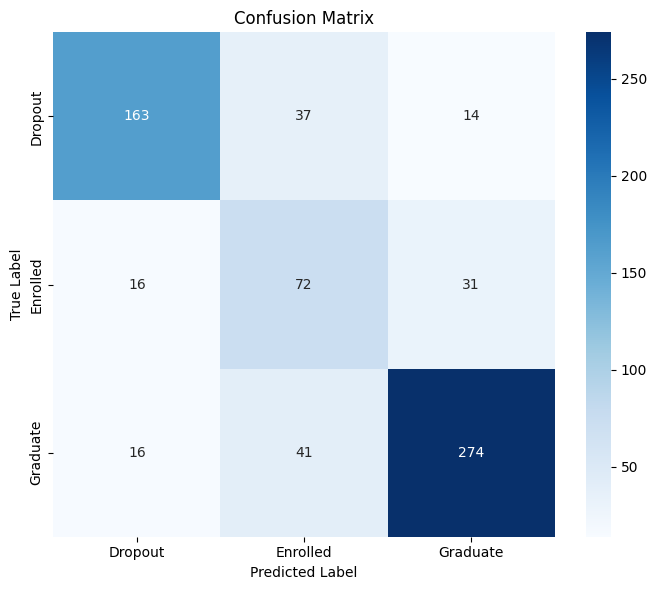

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

# 4-2
# تفسیر مدل

In [ ]:
# returns the output of the first hidden layer
def get_hidden_activations(model, X, layer_index):
    x = tf.convert_to_tensor(X, dtype=tf.float32)

    for i in range(len(model.dense_layers)):

        x = model.dense_layers[i](x)

        if model.bn_layers is not None:
            x = model.bn_layers[i](x, training=False)

        x = model.activation_layers[i](x)

        if model.dropout_layers is not None:
            x = model.dropout_layers[i](x, training=False)

        if i == layer_index:
            return x.numpy()

    raise ValueError("Invalid hidden layer index!")

In [ ]:
# Select at least 100 test samples
X_samples = x_test[:100].astype('float32')

# Select hidden layer (0 = first hidden layer)
layer_index = 1

# Extract neuron outputs
neuron_outputs = get_hidden_activations(
    best_model,
    X_samples,
    layer_index
)

print("Neuron outputs shape:", neuron_outputs.shape)

# save .csv
neuron_df = pd.DataFrame(neuron_outputs, columns=[f'Neuron_{i+1}' for i in range(neuron_outputs.shape[1])])
neuron_df.to_csv('Hidden_Layer_Outputs.csv', index=False)

Neuron outputs shape: (100, 64)


محاسبه ضریب همبستگی

In [ ]:
# Calculate Pearson correlation between neurons
correlation_matrix = neuron_df.corr(method='pearson')

# Save correlation matrix
correlation_matrix.to_csv('Neuron_Correlation.csv')

Heatmap

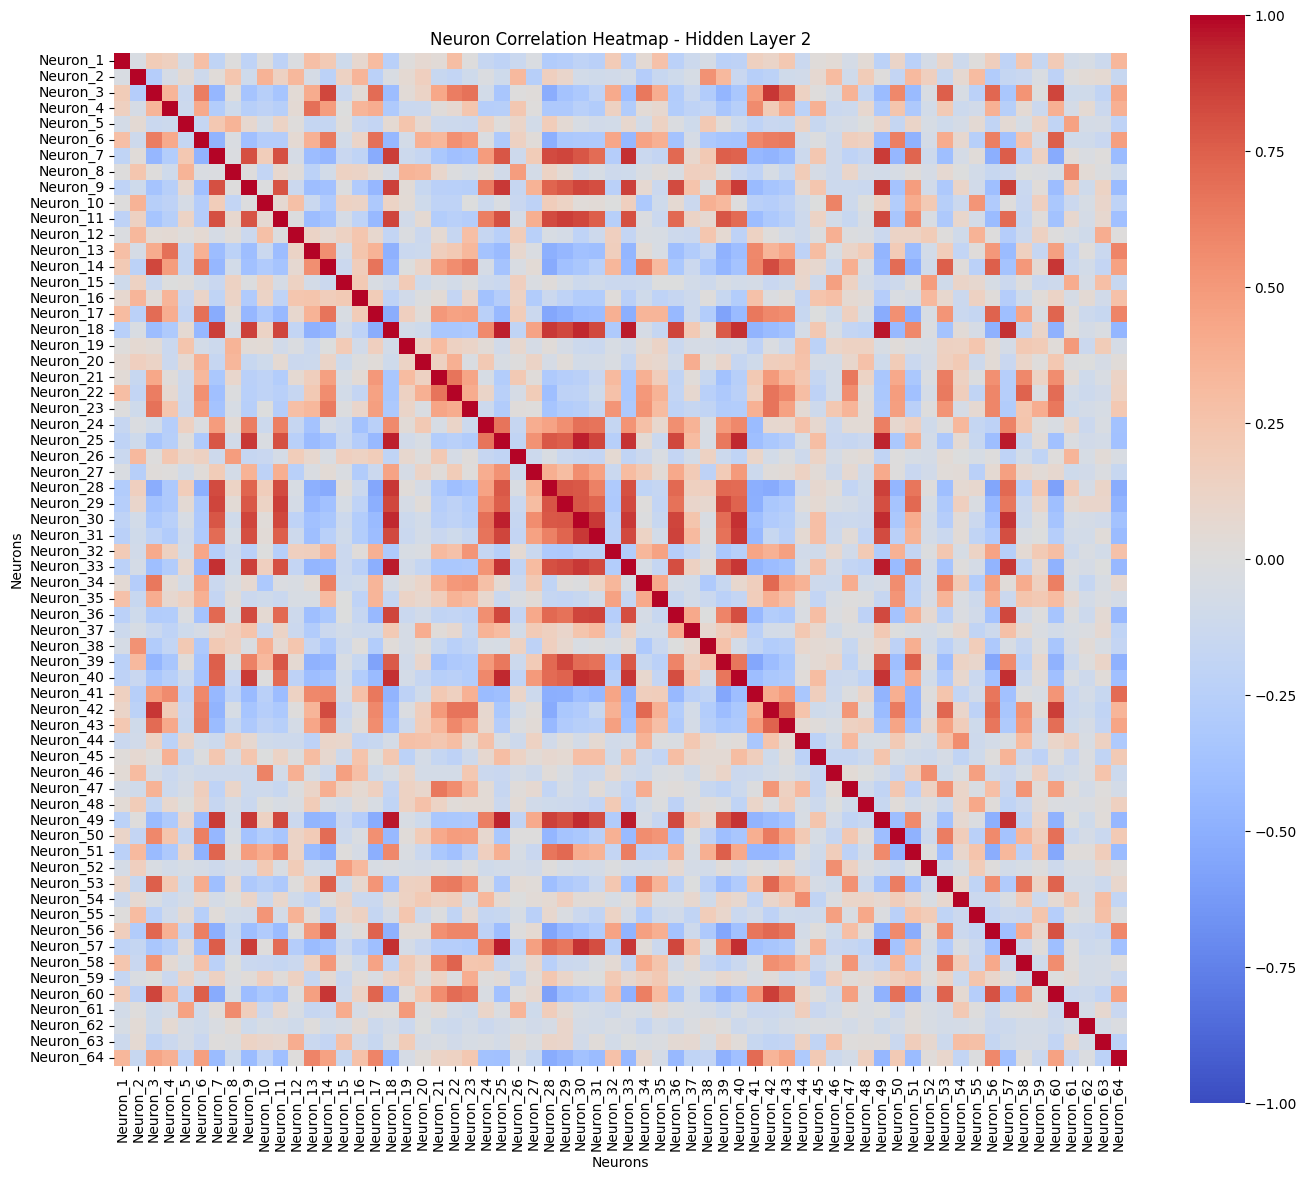

In [ ]:
plt.figure(figsize=(14, 12))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    xticklabels=True,
    yticklabels=True
)

plt.title(f'Neuron Correlation Heatmap - Hidden Layer {layer_index + 1}')
plt.xlabel('Neurons')
plt.ylabel('Neurons')
plt.tight_layout()

plt.show()

همبستگی بالا بین نورون های 18 و 49

غیرفعال کردن نورون های 18 و 49 (به ترتیب) و بررسی تاثیر آن روی عملکرد مدل

In [ ]:
def predict_with_neuron_disabled(model, X, layer_index, neuron_index):

    x = tf.convert_to_tensor(X, dtype=tf.float32)

    for i in range(len(model.dense_layers)):

        x = model.dense_layers[i](x)

        if model.bn_layers is not None:
            x = model.bn_layers[i](x, training=False)

        x = model.activation_layers[i](x)

        if model.dropout_layers is not None:
            x = model.dropout_layers[i](x, training=False)

        # Disable selected neuron
        if i == layer_index:
            x = tf.concat([
                x[:, :neuron_index],
                tf.zeros_like(x[:, neuron_index:neuron_index+1]),
                x[:, neuron_index+1:]
            ], axis=1)

    return model.output_layer(x).numpy()

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

y_true = np.asarray(y_test).flatten()

# Original model
y_original_prob = best_model.predict(
    x_test.astype('float32'), verbose=0
)
y_original = np.argmax(y_original_prob, axis=1)

# Disable Neuron 18
y_without_18_prob = predict_with_neuron_disabled(
    best_model, x_test, layer_index=1, neuron_index=17
)
y_without_18 = np.argmax(y_without_18_prob, axis=1)

# Disable Neuron 49
y_without_49_prob = predict_with_neuron_disabled(
    best_model, x_test, layer_index=1, neuron_index=48
)
y_without_49 = np.argmax(y_without_49_prob, axis=1)


# Compare performance
results = {
    'Original': y_original,
    'Without Neuron 18': y_without_18,
    'Without Neuron 49': y_without_49
}

for name, predictions in results.items():

    acc = accuracy_score(y_true, predictions)

    macro_f1 = f1_score(
        y_true, predictions,
        average='macro',
        zero_division=0
    )

    print(f'{name}:')
    print(f'  Accuracy : {acc:.4f}')
    print(f'  Macro F1 : {macro_f1:.4f}')
    print("====================")

Original:
  Accuracy : 0.7666
  Macro F1 : 0.7252
Without Neuron 18:
  Accuracy : 0.7636
  Macro F1 : 0.7213
Without Neuron 49:
  Accuracy : 0.7681
  Macro F1 : 0.7284


انتخاب یکی از ویژگی های عددی و تغییر مقدار آن از حداقل تا حداکثر و بررسی نتیجه

In [ ]:
feature = 'Curricular units 2nd sem (grade)'

# Select the first sample from the training set
sample_index = x_train.index[0]

# Original (unscaled) sample
sample_original = x.loc[[sample_index]].copy()
sample_label = y.loc[[sample_index]]

# Corresponding scaled sample for model input
sample_scaled = x_train.loc[[sample_index]].copy()

# Display original sample
print("Selected sample (original data):")
display(sample_original)
print("Sample Label:")
display(sample_label)

# Calculate min and max from the entire original dataset
grade_min = x[feature].min()
grade_max = x[feature].max()

print(f"Minimum grade in x: {grade_min}")
print(f"Maximum grade in x: {grade_max}")

Selected sample (original data):


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
3742,1,17,1,9670,1,1,118.0,1,19,38,...,0,0,6,6,6,14.0,0,12.4,0.5,1.79


Sample Label:


,Target
3742,Graduate


Minimum grade in x: 0.0
Maximum grade in x: 18.57142857


تغییر تدریجی ویژگی و پیش بینی توسط مدل

In [ ]:
# Generate 100 values in the original grade range
grade_values = np.linspace(grade_min, grade_max, 100)

# Find the feature position in the scaler
feature_index = list(scaler.feature_names_in_).index(feature)

# Convert generated values to StandardScaler values
scaled_grade_values = (
    grade_values - scaler.mean_[feature_index]
) / scaler.scale_[feature_index]

predictions = []

for scaled_grade in scaled_grade_values:

    # Copy the original scaled sample
    modified_sample = sample_scaled.copy()

    # Replace only the selected feature
    modified_sample.loc[:, feature] = scaled_grade

    # Predict probabilities
    probabilities = best_model.predict(
        modified_sample.astype('float32'),
        verbose=0
    )[0]

    predictions.append(probabilities)

predictions = np.array(predictions)

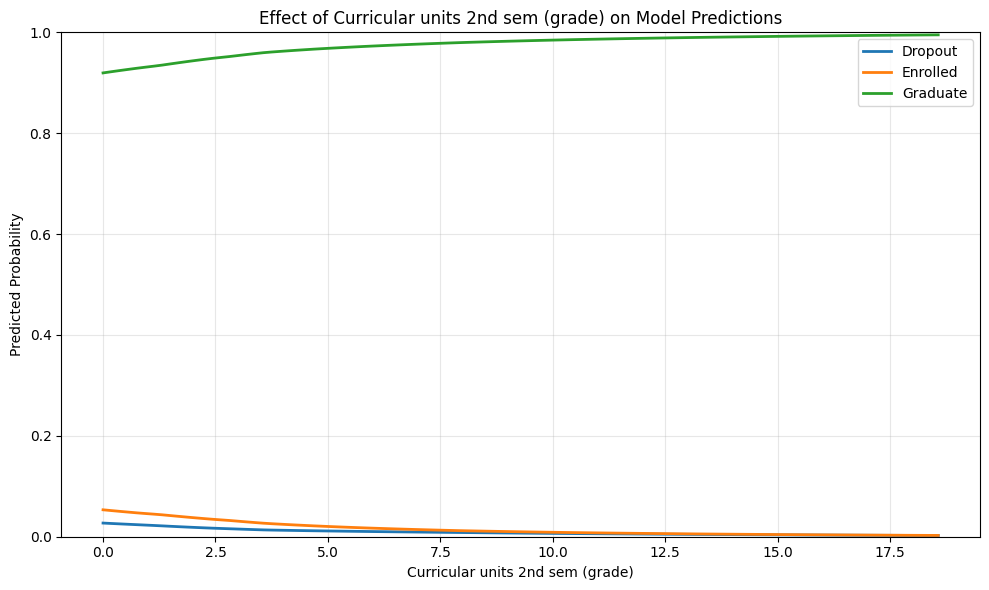

In [ ]:
class_names = ['Dropout', 'Enrolled', 'Graduate']

plt.figure(figsize=(10, 6))

for i, class_name in enumerate(class_names):
    plt.plot(
        grade_values,
        predictions[:, i],
        label=class_name,
        linewidth=2
    )

plt.xlabel('Curricular units 2nd sem (grade)')
plt.ylabel('Predicted Probability')
plt.title('Effect of Curricular units 2nd sem (grade) on Model Predictions')

plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()